In [1]:
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.special import logsumexp
from sklearn.neural_network import BernoulliRBM


## Finding a working RBM prior

In [2]:
def make_bars_and_stripes(n: int) -> np.ndarray:
    """
    Generate the n x n Bars-and-Stripes dataset as flattened binary vectors.

    Bars: each row is constant across columns.
    Stripes: each column is constant across rows.
    """
    images = []

    # Bars: choose one bit per row
    for row_bits in product([0, 1], repeat=n):
        img = np.array(row_bits)[:, None] * np.ones((1, n), dtype=int)
        images.append(img.astype(int).ravel())

    # Stripes: choose one bit per column
    for col_bits in product([0, 1], repeat=n):
        img = np.ones((n, 1), dtype=int) * np.array(col_bits)[None, :]
        images.append(img.astype(int).ravel())

    # Remove duplicates, e.g. all-zero and all-one appear twice
    images = np.unique(np.array(images, dtype=int), axis=0)
    return images

def sample_bars_and_stripes(n: int, n_samples: int, rng=None) -> np.ndarray:
    """
    Randomly sample n x n BAS images.

    With probability 1/2, sample bars.
    With probability 1/2, sample stripes.
    """
    rng = np.random.default_rng() if rng is None else rng
    images = []

    for _ in range(n_samples):
        if rng.random() < 0.5:
            # Bars: one bit per row
            row_bits = rng.integers(0, 2, size=n)
            img = row_bits[:, None] * np.ones((1, n), dtype=int)
        else:
            # Stripes: one bit per column
            col_bits = rng.integers(0, 2, size=n)
            img = np.ones((n, 1), dtype=int) * col_bits[None, :]

        images.append(img.ravel())

    return np.array(images, dtype=int)

def add_bitflip_noise(x: np.ndarray, sigma: float, rng=None) -> np.ndarray:
    """
    Binary salt-and-pepper noise: flip each bit independently with probability sigma.
    """
    rng = np.random.default_rng() if rng is None else rng
    flips = rng.random(x.shape) < sigma
    return np.bitwise_xor(x.astype(int), flips.astype(int))

def add_exact_k_bitflip_noise(
    x: np.ndarray,
    k: int,
    rng=None,
):
    """
    Flip exactly k randomly selected bits.

    This is not the same as independent Bernoulli noise, but it is useful
    for controlled visual examples.
    """
    rng = np.random.default_rng() if rng is None else rng
    x = np.asarray(x, dtype=int)

    if k < 0 or k > len(x):
        raise ValueError(f"k must satisfy 0 <= k <= {len(x)}")

    noisy = x.copy()
    flip_idx = rng.choice(len(x), size=k, replace=False)
    noisy[flip_idx] = 1 - noisy[flip_idx]

    return noisy, flip_idx

In [3]:
def rbm_to_qubo_upper(W: np.ndarray, bv: np.ndarray, bh: np.ndarray) -> np.ndarray:
    """
    Build upper-triangular QUBO matrix for

        E(v,h) = v^T W h + bv^T v + bh^T h.

    Variables are ordered as x = [v_0, ..., v_{n_v-1}, h_0, ..., h_{n_h-1}].
    """
    n_visible, n_hidden = W.shape
    n_total = n_visible + n_hidden

    Q = np.zeros((n_total, n_total), dtype=float)

    # Visible biases
    Q[np.arange(n_visible), np.arange(n_visible)] = bv

    # Hidden biases
    hidden_idx = n_visible + np.arange(n_hidden)
    Q[hidden_idx, hidden_idx] = bh

    # Visible-hidden couplings
    Q[:n_visible, n_visible:] = W

    return Q


def apply_denoising_diagonal_update(
    Q: np.ndarray,
    noisy_visible: np.ndarray,
    rho: float,
) -> np.ndarray:
    """
    Apply the Kerger & Miyazaki QUBO denoising update:

        Q_ii <- Q_ii + rho * (1 - 2 * noisy_visible_i)

    only for visible variables.
    """
    Q_tilde = Q.copy()
    n_visible = len(noisy_visible)
    idx = np.arange(n_visible)
    Q_tilde[idx, idx] += rho * (1 - 2 * noisy_visible)
    return Q_tilde


def enumerate_binary_states(n: int) -> np.ndarray:
    """
    Enumerate all binary states of length n.

    Returns an array of shape (2**n, n), where each row is a binary vector.
    Uses little-endian bit order: column 0 is the least significant bit.
    """
    if n < 0:
        raise ValueError("n must be nonnegative")

    if n >= 63:
        raise ValueError(
            "This bit-shift enumeration is only intended for small n. "
            "Brute force is infeasible for n >= 63 anyway."
        )

    nums = np.arange(2**n, dtype=np.uint64)
    shifts = np.arange(n, dtype=np.uint64)

    bits = ((nums[:, None] >> shifts[None, :]) & np.uint64(1)).astype(np.int8)
    return bits


def qubo_energy_upper(Q: np.ndarray, X: np.ndarray) -> np.ndarray:
    """
    Evaluate upper-triangular QUBO energy:

        E(x) = sum_i Q_ii x_i + sum_{i<j} Q_ij x_i x_j.

    X may be shape (n,) or (batch, n).
    """
    X = np.atleast_2d(X).astype(float)

    diag = np.einsum("bi,i->b", X, np.diag(Q))
    offdiag = np.einsum("bi,ij,bj->b", X, np.triu(Q, k=1), X)

    return diag + offdiag

In [4]:
def brute_force_qubo(Q: np.ndarray):
    """
    Solve a small QUBO exactly by exhaustive enumeration.
    """
    n = Q.shape[0]
    states = enumerate_binary_states(n)
    energies = qubo_energy_upper(Q, states)
    best_idx = np.argmin(energies)
    return states[best_idx], energies[best_idx], states, energies


def overlap_accuracy(clean: np.ndarray, recovered: np.ndarray) -> float:
    """
    Proportion of pixels matching the clean image.
    """
    return np.mean(clean.astype(int) == recovered.astype(int))

In [5]:
def solve_and_show_for_rho(Q, noisy_visible, clean_visible, n_side, n_visible, rho, label):
    Q_denoise = apply_denoising_diagonal_update(
        Q,
        noisy_visible=noisy_visible,
        rho=rho,
    )

    best_state, best_energy, states, energies = brute_force_qubo(Q_denoise)
    recovered_visible = best_state[:n_visible]

    print(f"\n--- {label} ---")
    print("rho:", rho)
    print("Recovered:")
    print(recovered_visible.reshape(n_side, n_side))
    print("Recovered accuracy:", overlap_accuracy(clean_visible, recovered_visible))
    print("Best energy:", best_energy)

    return recovered_visible, best_energy

## Using BernoulliRBM - did not work

In [6]:
rng_seed = 123
rng = np.random.default_rng(rng_seed)

# ----------------------------
# Dataset
# ----------------------------
n_side = 3
# X_train = make_bars_and_stripes(n_side)
X_unique = make_bars_and_stripes(n_side)
X_train = sample_bars_and_stripes(n_side, n_samples=4000, rng=rng)

n_visible = X_train.shape[1]
n_hidden = 10

n_iter = 3000

# bitflip chance
sigma = 0.15

# These are the values used in the Kerger & Miyazaki paper for the exact and robust denoising experiments.
rho_exact = np.log((1 - sigma) / sigma)
rho_robust = np.log((1 - 0.75 * sigma) / (0.75 * sigma))

In [7]:
# ----------------------------
# Train tiny RBM
# ----------------------------
rbm = BernoulliRBM(
    n_components=n_hidden,
    learning_rate=0.05,
    batch_size=min(100, len(X_train)),
    n_iter=n_iter,
    random_state=0,
    verbose=False,
)

rbm.fit(X_train)

# Convert sklearn parameters to Kerger & Miyazakis energy convention:
# E(v,h) = v^T W h + bv^T v + bh^T h
W = -rbm.components_.T
bv = -rbm.intercept_visible_
bh = -rbm.intercept_hidden_

Q_b = rbm_to_qubo_upper(W, bv, bh)

# ----------------------------
# Pick a clean image and corrupt it
# ----------------------------
clean_visible = X_unique[3]
noisy_visible = add_bitflip_noise(clean_visible, sigma=sigma, rng=rng)
# noisy_visible = add_exact_k_bitflip_noise(clean_visible, k=1, rng=rng)[0]

Q_denoise = apply_denoising_diagonal_update(
    Q_b,
    noisy_visible=noisy_visible,
    rho=rho_robust,
)

# ----------------------------
# Solve denoising QUBO exactly
# ----------------------------
best_state, best_energy, states, energies = brute_force_qubo(Q_denoise)

recovered_visible = best_state[:n_visible]

print("Clean:")
print(clean_visible.reshape(n_side, n_side))

print("\nNoisy:")
print(noisy_visible.reshape(n_side, n_side))

print("\nRecovered:")
print(recovered_visible.reshape(n_side, n_side))

print("\nNoisy accuracy:", overlap_accuracy(clean_visible, noisy_visible))
print("Recovered accuracy:", overlap_accuracy(clean_visible, recovered_visible))
print("Best energy:", best_energy)

Clean:
[[0 0 0]
 [1 1 1]
 [1 1 1]]

Noisy:
[[0 0 0]
 [1 1 1]
 [1 1 1]]

Recovered:
[[0 0 0]
 [1 1 1]
 [1 1 1]]

Noisy accuracy: 1.0
Recovered accuracy: 1.0
Best energy: -57.16762472433852


In [8]:
rho_values = [
    (0.0, "rho = 0"),
    (0.25, "rho = 0.25"),
    (0.5, "rho = 0.5"),
    (1.0, "rho = 1.0"),
    (rho_exact, "rho exact"),
    (rho_robust, "rho robust"),
]

results = []
print("Clean:")
print(clean_visible.reshape(n_side, n_side))

print("\nNoisy:")
print(noisy_visible.reshape(n_side, n_side))
for rho, label in rho_values:
    results.append(solve_and_show_for_rho(Q_b, noisy_visible, clean_visible, n_side, n_visible, rho, label))

Clean:
[[0 0 0]
 [1 1 1]
 [1 1 1]]

Noisy:
[[0 0 0]
 [1 1 1]
 [1 1 1]]

--- rho = 0 ---
rho: 0.0
Recovered:
[[1 1 1]
 [1 1 1]
 [0 0 0]]
Recovered accuracy: 0.3333333333333333
Best energy: -57.02228667169557

--- rho = 0.25 ---
rho: 0.25
Recovered:
[[1 1 1]
 [1 1 1]
 [0 0 0]]
Recovered accuracy: 0.3333333333333333
Best energy: -57.02228667169557

--- rho = 0.5 ---
rho: 0.5
Recovered:
[[1 1 1]
 [1 1 1]
 [0 0 0]]
Recovered accuracy: 0.3333333333333333
Best energy: -57.02228667169557

--- rho = 1.0 ---
rho: 1.0
Recovered:
[[1 1 1]
 [1 1 1]
 [0 0 0]]
Recovered accuracy: 0.3333333333333333
Best energy: -57.02228667169557

--- rho exact ---
rho: 1.7346010553881064
Recovered:
[[1 1 1]
 [1 1 1]
 [0 0 0]]
Recovered accuracy: 0.3333333333333333
Best energy: -57.02228667169557

--- rho robust ---
rho: 2.065455299705096
Recovered:
[[0 0 0]
 [1 1 1]
 [1 1 1]]
Recovered accuracy: 1.0
Best energy: -57.16762472433852


In [9]:
def min_energy_for_visible(Q, visible):
    """
    Given fixed visible bits, minimize the QUBO over all hidden states.
    """
    n_total = Q.shape[0]
    n_visible = len(visible)
    n_hidden = n_total - n_visible

    hidden_states = enumerate_binary_states(n_hidden)

    states = np.zeros((len(hidden_states), n_total), dtype=int)
    states[:, :n_visible] = visible[None, :]
    states[:, n_visible:] = hidden_states

    energies = qubo_energy_upper(Q, states)
    best_idx = np.argmin(energies)

    return energies[best_idx], states[best_idx]


for rho, label in rho_values:
    Q_denoise = apply_denoising_diagonal_update(Q_b, noisy_visible, rho)

    E_clean, state_clean = min_energy_for_visible(Q_denoise, clean_visible)
    E_noisy, state_noisy = min_energy_for_visible(Q_denoise, noisy_visible)

    print(f"\n--- {label} ---")
    print("E(clean visible, best hidden):", E_clean)
    print("E(noisy visible, best hidden):", E_noisy)
    print("Clean - Noisy:", E_clean - E_noisy)


--- rho = 0 ---
E(clean visible, best hidden): -44.77489292610795
E(noisy visible, best hidden): -44.77489292610795
Clean - Noisy: 0.0

--- rho = 0.25 ---
E(clean visible, best hidden): -46.27489292610795
E(noisy visible, best hidden): -46.27489292610795
Clean - Noisy: 0.0

--- rho = 0.5 ---
E(clean visible, best hidden): -47.77489292610795
E(noisy visible, best hidden): -47.77489292610795
Clean - Noisy: 0.0

--- rho = 1.0 ---
E(clean visible, best hidden): -50.77489292610795
E(noisy visible, best hidden): -50.77489292610795
Clean - Noisy: 0.0

--- rho exact ---
E(clean visible, best hidden): -55.18249925843659
E(noisy visible, best hidden): -55.18249925843659
Clean - Noisy: 0.0

--- rho robust ---
E(clean visible, best hidden): -57.16762472433852
E(noisy visible, best hidden): -57.16762472433852
Clean - Noisy: 0.0


In [10]:
def visible_model_score(Q, visible):
    """
    Lower is better. Minimizes over hidden states.
    This is not the true marginal probability.
    """
    E, _ = min_energy_for_visible(Q, visible)
    return E


print("RBM visible scores on all BAS training images:")
scores = []
for idx, img in enumerate(X_train):
    score = visible_model_score(Q_b, img)
    scores.append(score)
    print(idx, score, img.reshape(n_side, n_side), sep="\n")

print("\nClean score:", visible_model_score(Q_b, clean_visible))
print("Noisy score:", visible_model_score(Q_b, noisy_visible))

RBM visible scores on all BAS training images:
0
-52.42551608993463
[[1 0 1]
 [1 0 1]
 [1 0 1]]
1
-50.2726888818315
[[0 0 0]
 [0 0 0]
 [0 0 0]]
2
-51.76883843553466
[[0 1 0]
 [0 1 0]
 [0 1 0]]
3
-49.9028706888451
[[0 1 1]
 [0 1 1]
 [0 1 1]]
4
-50.2726888818315
[[0 0 0]
 [0 0 0]
 [0 0 0]]
5
-45.938958100887625
[[1 1 1]
 [0 0 0]
 [1 1 1]]
6
-49.9028706888451
[[0 1 1]
 [0 1 1]
 [0 1 1]]
7
-52.66347174764449
[[0 0 1]
 [0 0 1]
 [0 0 1]]
8
-50.2726888818315
[[0 0 0]
 [0 0 0]
 [0 0 0]]
9
-50.2726888818315
[[0 0 0]
 [0 0 0]
 [0 0 0]]
10
-50.2726888818315
[[0 0 0]
 [0 0 0]
 [0 0 0]]
11
-52.42551608993463
[[1 0 1]
 [1 0 1]
 [1 0 1]]
12
-45.163184079272725
[[1 1 0]
 [1 1 0]
 [1 1 0]]
13
-52.66347174764449
[[0 0 1]
 [0 0 1]
 [0 0 1]]
14
-48.363832364455305
[[0 0 0]
 [1 1 1]
 [0 0 0]]
15
-43.45601829039599
[[1 1 1]
 [1 1 1]
 [1 1 1]]
16
-44.77489292610795
[[0 0 0]
 [1 1 1]
 [1 1 1]]
17
-51.76883843553466
[[0 1 0]
 [0 1 0]
 [0 1 0]]
18
-50.19544657187538
[[0 0 0]
 [0 0 0]
 [1 1 1]]
19
-48.3638323644

In [11]:
def visible_free_energy_exact(Q: np.ndarray, visible: np.ndarray) -> float:
    """
    Exact visible free energy under the QUBO/RBM model:

        F(v) = -log sum_h exp(-E(v,h))

    Lower F(v) means higher model probability for visible image v.
    """
    n_total = Q.shape[0]
    n_visible = len(visible)
    n_hidden = n_total - n_visible

    hidden_states = enumerate_binary_states(n_hidden)

    states = np.zeros((len(hidden_states), n_total), dtype=int)
    states[:, :n_visible] = visible[None, :]
    states[:, n_visible:] = hidden_states

    energies = qubo_energy_upper(Q, states)

    return -logsumexp(-energies)


print("Best-hidden model score:")
print("Clean:", visible_model_score(Q_b, clean_visible))
print("Noisy:", visible_model_score(Q_b, noisy_visible))

print("\nExact visible free energy:")
print("Clean:", visible_free_energy_exact(Q_b, clean_visible))
print("Noisy:", visible_free_energy_exact(Q_b, noisy_visible))

print("\nRBM exact visible free energies on all BAS training images:")

free_energy_rows = []
for idx, img in enumerate(X_train):
    F = visible_free_energy_exact(Q_b, img)
    E_min = visible_model_score(Q_b, img)
    free_energy_rows.append((idx, F, E_min, img))

free_energy_rows = sorted(free_energy_rows, key=lambda row: row[1])

for idx, F, E_min, img in free_energy_rows:
    print("\nidx:", idx)
    print("free energy:", F)
    print("best-hidden energy:", E_min)
    print(img.reshape(n_side, n_side))

Best-hidden model score:
Clean: -44.77489292610795
Noisy: -44.77489292610795

Exact visible free energy:
Clean: -45.16591540595034
Noisy: -45.16591540595034

RBM exact visible free energies on all BAS training images:

idx: 22
free energy: -57.02385924648699
best-hidden energy: -57.02228667169557
[[1 1 1]
 [1 1 1]
 [0 0 0]]

idx: 24
free energy: -57.02385924648699
best-hidden energy: -57.02228667169557
[[1 1 1]
 [1 1 1]
 [0 0 0]]

idx: 25
free energy: -57.02385924648699
best-hidden energy: -57.02228667169557
[[1 1 1]
 [1 1 1]
 [0 0 0]]

idx: 37
free energy: -57.02385924648699
best-hidden energy: -57.02228667169557
[[1 1 1]
 [1 1 1]
 [0 0 0]]

idx: 39
free energy: -57.02385924648699
best-hidden energy: -57.02228667169557
[[1 1 1]
 [1 1 1]
 [0 0 0]]

idx: 41
free energy: -57.02385924648699
best-hidden energy: -57.02228667169557
[[1 1 1]
 [1 1 1]
 [0 0 0]]

idx: 46
free energy: -57.02385924648699
best-hidden energy: -57.02228667169557
[[1 1 1]
 [1 1 1]
 [0 0 0]]

idx: 57
free energy: -57.

In [12]:
def random_binary_images(n_visible: int, n_samples: int, rng=None) -> np.ndarray:
    rng = np.random.default_rng() if rng is None else rng
    return rng.integers(0, 2, size=(n_samples, n_visible), dtype=int)


def make_noisy_dataset(X: np.ndarray, sigma: float, rng=None) -> np.ndarray:
    rng = np.random.default_rng() if rng is None else rng
    return np.array([add_bitflip_noise(x, sigma, rng) for x in X], dtype=int)

sigma_test = 0.15
X_clean = X_unique
X_noisy = make_noisy_dataset(X_clean, sigma_test, rng)
X_random = random_binary_images(n_visible, len(X_clean), rng)

F_clean = np.array([visible_free_energy_exact(Q_b, x) for x in X_clean])
F_noisy = np.array([visible_free_energy_exact(Q_b, x) for x in X_noisy])
F_random = np.array([visible_free_energy_exact(Q_b, x) for x in X_random])

print("Mean free energy:")
print("Clean BAS:", F_clean.mean())
print("Noisy BAS:", F_noisy.mean())
print("Random:", F_random.mean())

print("\nClean better than noisy fraction:", np.mean(F_clean < F_noisy))
print("Clean better than random fraction:", np.mean(F_clean < F_random))

Mean free energy:
Clean BAS: -49.929543231813696
Noisy BAS: -41.01328944134739
Random: -35.16540595273786

Clean better than noisy fraction: 1.0
Clean better than random fraction: 1.0


## Using an Exact Maximum Likelihood RBM

In [13]:
def train_exact_rbm_mle(
    X_data: np.ndarray,
    n_hidden: int = 6,
    epochs: int = 3000,
    lr: float = 0.05,
    l2: float = 1e-4,
    seed: int = 0,
    print_every: int = 500,
):
    """
    Train a small RBM by exact maximum likelihood.

    Energy convention:
        E(v,h) = v^T W h + bv^T v + bh^T h

    Probability:
        p(v,h) ∝ exp(-E(v,h))
    """
    torch.manual_seed(seed)

    X = torch.tensor(X_data, dtype=torch.float64)
    n_visible = X.shape[1]

    V_all = torch.tensor(enumerate_binary_states(n_visible), dtype=torch.float64)
    H_all = torch.tensor(enumerate_binary_states(n_hidden), dtype=torch.float64)

    # Initialize near zero so the model starts close to uniform
    W = torch.nn.Parameter(0.01 * torch.randn(n_visible, n_hidden, dtype=torch.float64))
    bv = torch.nn.Parameter(torch.zeros(n_visible, dtype=torch.float64))
    bh = torch.nn.Parameter(torch.zeros(n_hidden, dtype=torch.float64))

    optimizer = torch.optim.Adam([W, bv, bh], lr=lr)

    def energy_grid(V):
        """
        Return E(V, H_all) with shape (num_V, num_H).
        """
        interaction = (V @ W) @ H_all.T
        visible_bias = (V @ bv)[:, None]
        hidden_bias = (H_all @ bh)[None, :]
        return interaction + visible_bias + hidden_bias

    for epoch in range(epochs):
        optimizer.zero_grad()

        E_data = energy_grid(X)
        log_num = torch.logsumexp(-E_data, dim=1)

        E_all = energy_grid(V_all)
        log_Z = torch.logsumexp(-E_all.reshape(-1), dim=0)

        neg_log_likelihood = -(log_num - log_Z).mean()

        reg = l2 * (torch.sum(W**2) + torch.sum(bv**2) + torch.sum(bh**2))
        loss = neg_log_likelihood + reg

        loss.backward()
        optimizer.step()

        if print_every and epoch % print_every == 0:
            print(f"epoch={epoch:5d} loss={loss.item():.6f} nll={neg_log_likelihood.item():.6f}")

    return (
        W.detach().cpu().numpy(),
        bv.detach().cpu().numpy(),
        bh.detach().cpu().numpy(),
    )

def evaluate_prior(Q, X_clean, sigma=0.15, n_noise_trials=20, seed=0):
    """
    Evaluate the RBM prior by comparing free energies of clean, noisy, and random images.
    """
    rng = np.random.default_rng(seed)
    n_visible = X_clean.shape[1]

    clean_repeated = []
    noisy_samples = []

    for _ in range(n_noise_trials):
        for x in X_clean:
            clean_repeated.append(x)
            noisy_samples.append(add_bitflip_noise(x, sigma=sigma, rng=rng))

    clean_repeated = np.array(clean_repeated, dtype=int)
    noisy_samples = np.array(noisy_samples, dtype=int)
    random_samples = random_binary_images(n_visible, len(clean_repeated), rng=rng)

    F_clean = np.array([visible_free_energy_exact(Q, x) for x in clean_repeated])
    F_noisy = np.array([visible_free_energy_exact(Q, x) for x in noisy_samples])
    F_random = np.array([visible_free_energy_exact(Q, x) for x in random_samples])

    print("Mean free energy:")
    print("Clean BAS:", F_clean.mean())
    print("Noisy BAS:", F_noisy.mean())
    print("Random:", F_random.mean())

    print("Clean better than noisy fraction:", np.mean(F_clean < F_noisy))
    print("Clean better than random fraction:", np.mean(F_clean < F_random))

    return {
        "F_clean": F_clean,
        "F_noisy": F_noisy,
        "F_random": F_random,
    }

In [14]:
W, bv, bh = train_exact_rbm_mle(
    X_train,
    n_hidden=n_hidden,
    epochs=n_iter,
    lr=0.05,
    l2=1e-4,
    seed=0,
    print_every=500,
)

Q_e = rbm_to_qubo_upper(W, bv, bh)

diagnostics = evaluate_prior(
    Q_e,
    X_unique,
    sigma=0.15,
    n_noise_trials=50,
    seed=rng_seed,
)

epoch=    0 loss=6.238913 nll=6.238912
epoch=  500 loss=2.790390 nll=2.644303
epoch= 1000 loss=2.776922 nll=2.636349
epoch= 1500 loss=2.752493 nll=2.628483
epoch= 2000 loss=2.751612 nll=2.628835
epoch= 2500 loss=2.752586 nll=2.629879
Mean free energy:
Clean BAS: -38.771535039268
Noisy BAS: -33.1614534972139
Random: -29.083715967555207
Clean better than noisy fraction: 0.7628571428571429
Clean better than random fraction: 0.9814285714285714


In [15]:
clean_visible = X_unique[3]

noisy_visible = add_bitflip_noise(clean_visible, sigma=sigma, rng=rng)

rho_values = [
    (0.0, "rho = 0"),
    (0.25, "rho = 0.25"),
    (0.5, "rho = 0.5"),
    (1.0, "rho = 1.0"),
    (rho_exact, "rho exact"),
    (rho_robust, "rho robust"),
]

print("Clean:")
print(clean_visible.reshape(n_side, n_side))

print("\nNoisy:")
print(noisy_visible.reshape(n_side, n_side))
for rho, label in rho_values:
    solve_and_show_for_rho(Q_e, noisy_visible, clean_visible, n_side, n_visible, rho, label)

Clean:
[[0 0 0]
 [1 1 1]
 [1 1 1]]

Noisy:
[[1 0 0]
 [1 1 1]
 [0 1 0]]

--- rho = 0 ---
rho: 0.0
Recovered:
[[1 1 1]
 [1 1 1]
 [1 1 1]]
Recovered accuracy: 0.6666666666666666
Best energy: -39.32452677243137

--- rho = 0.25 ---
rho: 0.25
Recovered:
[[1 1 1]
 [1 1 1]
 [1 1 1]]
Recovered accuracy: 0.6666666666666666
Best energy: -39.57452677243137

--- rho = 0.5 ---
rho: 0.5
Recovered:
[[0 0 0]
 [1 1 1]
 [0 0 0]]
Recovered accuracy: 0.6666666666666666
Best energy: -40.11707147474213

--- rho = 1.0 ---
rho: 1.0
Recovered:
[[0 0 0]
 [1 1 1]
 [0 0 0]]
Recovered accuracy: 0.6666666666666666
Best energy: -41.61707147474213

--- rho exact ---
rho: 1.7346010553881064
Recovered:
[[0 0 0]
 [1 1 1]
 [0 0 0]]
Recovered accuracy: 0.6666666666666666
Best energy: -43.82087464090645

--- rho robust ---
rho: 2.065455299705096
Recovered:
[[0 0 0]
 [1 1 1]
 [0 0 0]]
Recovered accuracy: 0.6666666666666666
Best energy: -44.813437373857425


In [16]:
for rho, label in rho_values:
    Q_denoise = apply_denoising_diagonal_update(Q_e, noisy_visible, rho)

    E_clean, _ = min_energy_for_visible(Q_denoise, clean_visible)
    E_noisy, _ = min_energy_for_visible(Q_denoise, noisy_visible)

    print(f"\n--- {label} ---")
    print("E(clean visible, best hidden):", E_clean)
    print("E(noisy visible, best hidden):", E_noisy)
    print("Clean - Noisy:", E_clean - E_noisy)


--- rho = 0 ---
E(clean visible, best hidden): -38.63779537856047
E(noisy visible, best hidden): -25.30333234770869
Clean - Noisy: -13.33446303085178

--- rho = 0.25 ---
E(clean visible, best hidden): -39.13779537856047
E(noisy visible, best hidden): -26.55333234770869
Clean - Noisy: -12.58446303085178

--- rho = 0.5 ---
E(clean visible, best hidden): -39.63779537856047
E(noisy visible, best hidden): -27.80333234770869
Clean - Noisy: -11.83446303085178

--- rho = 1.0 ---
E(clean visible, best hidden): -40.637795378560455
E(noisy visible, best hidden): -30.303332347708682
Clean - Noisy: -10.334463030851772

--- rho exact ---
E(clean visible, best hidden): -42.10699748933668
E(noisy visible, best hidden): -33.97633762464921
Clean - Noisy: -8.130659864687466

--- rho robust ---
E(clean visible, best hidden): -42.768705977970654
E(noisy visible, best hidden): -35.63060884623417
Clean - Noisy: -7.138097131736487


In [17]:
def exact_denoising_experiment(
    Q,
    X_clean,
    sigma_values,
    rho_mode="robust",
    n_noise_trials=20,
    rng=None,
):
    """
    Run the exact denoising experiment for a range of noise levels and return results as a list of dicts.
    """
    if rng is None:
        rng = np.random.default_rng()
        
    rows = []

    for sigma in sigma_values:
        for trial in range(n_noise_trials):
            for idx, clean in enumerate(X_clean):
                noisy = add_bitflip_noise(clean, sigma=sigma, rng=rng)

                if rho_mode == "exact":
                    rho = np.log((1 - sigma) / sigma)
                elif rho_mode == "robust":
                    rho = np.log((1 - 0.75 * sigma) / (0.75 * sigma))
                else:
                    raise ValueError("rho_mode must be 'exact' or 'robust'")

                Q_denoise = apply_denoising_diagonal_update(Q, noisy, rho)
                best_state, best_energy, _, _ = brute_force_qubo(Q_denoise)

                recovered = best_state[:len(clean)]

                rows.append({
                    "sigma": sigma,
                    "trial": trial,
                    "image_idx": idx,
                    "rho_mode": rho_mode,
                    "noisy_acc": overlap_accuracy(clean, noisy),
                    "recovered_acc": overlap_accuracy(clean, recovered),
                    "improvement": overlap_accuracy(clean, recovered) - overlap_accuracy(clean, noisy),
                    "energy": best_energy,
                })

    return rows

In [18]:
sigma_values = [0.05, 0.10, 0.15, 0.20, 0.25]

rows_exact = exact_denoising_experiment(
    Q_e,
    X_unique,
    sigma_values,
    rho_mode="exact",
    n_noise_trials=20,
    rng=rng,
)

rows_robust = exact_denoising_experiment(
    Q_e,
    X_unique,
    sigma_values,
    rho_mode="robust",
    n_noise_trials=20,
    rng=rng,
)

df = pd.DataFrame(rows_exact + rows_robust)

summary = (
    df.groupby(["rho_mode", "sigma"])
      [["noisy_acc", "recovered_acc", "improvement"]]
      .mean()
      .reset_index()
)

summary

,rho_mode,sigma,noisy_acc,recovered_acc,improvement
0,exact,0.05,0.955556,0.986905,0.031349
1,exact,0.10,0.892857,0.942460,0.049603
2,exact,0.15,0.853571,0.915079,0.061508
3,exact,0.20,0.800000,0.840873,0.040873
4,exact,0.25,0.730952,0.763095,0.032143
5,robust,0.05,0.951984,0.981746,0.029762
6,robust,0.10,0.905556,0.953175,0.047619
7,robust,0.15,0.857143,0.918254,0.061111
8,robust,0.20,0.793254,0.832937,0.039683
9,robust,0.25,0.748413,0.780556,0.032143


In [19]:
print("Exact Denoising MLE Parameters:")
print("W:\n", W)
print("bv:\n", bv)
print("bh:\n", bh)

Exact Denoising MLE Parameters:
W:
 [[-1.78405271  0.59149038  3.53000718  3.70424064 -2.01365809  3.35723291
   5.26607571 -3.91628667  1.51465603 -1.8954369 ]
 [ 3.72514435  2.30561375 -1.67363752 -1.60109847 -1.82975556  5.54295422
   3.7020587  -3.16910565 -3.14641973 -1.66389055]
 [-1.95282128  2.21873725 -1.9694227  -1.86178538  3.36494874  3.38382259
   3.43269317 -5.73643435  1.79460909  3.45399559]
 [ 3.3648419  -0.85691654  3.32895348  5.45148811 -2.2647016  -2.26922661
   3.32040981  0.60734874  0.59763498  3.35802229]
 [ 5.28278401  0.52976489 -1.90440441  3.68329606 -2.00462644  3.33685056
  -1.79110631  1.52517197 -3.88466302  3.54172066]
 [ 3.55409171  0.51305516 -1.78602753  3.68738997  3.34152376 -2.00010493
  -1.89972164 -3.88260662  1.52178174  5.28048539]
 [-1.89815427  0.62238945  5.26841964  3.699634    3.3510531  -2.01581128
   3.52332454  1.5240428  -3.90943434 -1.78665806]
 [ 3.45115569  2.25970336  3.42828034 -1.86999326  3.37109289  3.36362215
  -1.97189778  

## Contrastive Divergence RBM

In [20]:
def sigmoid(x):
    # Numerically stable enough
    return 1.0 / (1.0 + np.exp(-x))


def sample_bernoulli(prob, rng):
    return (rng.random(prob.shape) < prob).astype(np.float64)


def train_cd_rbm(
    X_data: np.ndarray,
    n_hidden: int = 6,
    epochs: int = 1000,
    batch_size: int = 64,
    lr: float = 0.05,
    k: int = 1,
    momentum: float = 0.5,
    final_momentum: float = 0.9,
    momentum_switch_epoch: int = 50,
    weight_decay: float = 1e-4,
    rng = None,
    print_every: int = 100,
    persistent: bool = False,
):
    """
    Train a binary-binary RBM with Contrastive Divergence CD-k.

    Training convention:
        score(v,h) = v^T A h + av^T v + ah^T h
        p(v,h) ∝ exp(score(v,h))

    Returned convention:
        E(v,h) = v^T W h + bv^T v + bh^T h
        p(v,h) ∝ exp(-E(v,h))

    Therefore:
        W  = -A
        bv = -av
        bh = -ah
    """
    if rng is None:
        rng = np.random.default_rng()

    X = np.asarray(X_data, dtype=np.float64)
    n_samples, n_visible = X.shape

    # Score-convention parameters.
    A = 0.01 * rng.normal(size=(n_visible, n_hidden))
    av = np.zeros(n_visible, dtype=np.float64)
    ah = np.zeros(n_hidden, dtype=np.float64)

    # Momentum buffers.
    dA_prev = np.zeros_like(A)
    dav_prev = np.zeros_like(av)
    dah_prev = np.zeros_like(ah)

    persistent_v = None

    losses = []

    for epoch in range(epochs):
        perm = rng.permutation(n_samples)
        X_shuffled = X[perm]

        epoch_recon_error = 0.0
        n_seen = 0

        mom = final_momentum if epoch >= momentum_switch_epoch else momentum

        for start in range(0, n_samples, batch_size):
            v0 = X_shuffled[start:start + batch_size]
            m = len(v0)
            n_seen += m

            # Positive phase.
            ph0 = sigmoid(v0 @ A + ah)
            h0_sample = sample_bernoulli(ph0, rng)

            # Negative chain initialization.
            if persistent:
                if persistent_v is None or len(persistent_v) != m:
                    vk = v0.copy()
                else:
                    vk = persistent_v.copy()
                hk = sample_bernoulli(sigmoid(vk @ A + ah), rng)
            else:
                vk = v0.copy()
                hk = h0_sample.copy()

            # CD-k Gibbs chain.
            for _ in range(k):
                pvk = sigmoid(hk @ A.T + av)
                vk = sample_bernoulli(pvk, rng)

                phk = sigmoid(vk @ A + ah)
                hk = sample_bernoulli(phk, rng)

            if persistent:
                persistent_v = vk.copy()

            # Use probabilities for hidden expectations to reduce variance.
            phk = sigmoid(vk @ A + ah)

            # Positive and negative statistics.
            pos_A = v0.T @ ph0 / m
            neg_A = vk.T @ phk / m

            pos_av = v0.mean(axis=0)
            neg_av = vk.mean(axis=0)

            pos_ah = ph0.mean(axis=0)
            neg_ah = phk.mean(axis=0)

            # CD update in score convention:
            # A += lr * (positive - negative)
            dA = lr * (pos_A - neg_A - weight_decay * A)
            dav = lr * (pos_av - neg_av)
            dah = lr * (pos_ah - neg_ah)

            # Momentum.
            dA_total = mom * dA_prev + dA
            dav_total = mom * dav_prev + dav
            dah_total = mom * dah_prev + dah

            A += dA_total
            av += dav_total
            ah += dah_total

            dA_prev = dA_total
            dav_prev = dav_total
            dah_prev = dah_total

            # Reconstruction error diagnostic.
            epoch_recon_error += np.sum((v0 - pvk) ** 2)

        epoch_recon_error /= n_seen
        losses.append(epoch_recon_error)

        if print_every and epoch % print_every == 0:
            print(f"epoch={epoch:5d} recon_mse={epoch_recon_error:.6f}")

    # Convert to Miyazaki & Kerger energy convention.
    W = -A
    bv = -av
    bh = -ah

    return W, bv, bh, {
        "recon_mse": np.array(losses),
        "A_score": A,
        "av_score": av,
        "ah_score": ah,
    }

In [21]:
W_cd, bv_cd, bh_cd, cd_info = train_cd_rbm(
    X_train,
    n_hidden=n_hidden,
    epochs=n_iter,
    batch_size=64,
    lr=0.05,
    k=1,
    momentum=0.5,
    final_momentum=0.9,
    momentum_switch_epoch=50,
    weight_decay=1e-4,
    rng=rng,
    print_every=100,
    persistent=False,
)

Q_cd = rbm_to_qubo_upper(W_cd, bv_cd, bh_cd)

epoch=    0 recon_mse=2.252623
epoch=  100 recon_mse=0.002579
epoch=  200 recon_mse=0.001380
epoch=  300 recon_mse=0.001038
epoch=  400 recon_mse=0.001445
epoch=  500 recon_mse=0.001198
epoch=  600 recon_mse=0.001065
epoch=  700 recon_mse=0.001106
epoch=  800 recon_mse=0.000724
epoch=  900 recon_mse=0.001126
epoch= 1000 recon_mse=0.000978
epoch= 1100 recon_mse=0.000862
epoch= 1200 recon_mse=0.000964
epoch= 1300 recon_mse=0.000661
epoch= 1400 recon_mse=0.000718
epoch= 1500 recon_mse=0.001376
epoch= 1600 recon_mse=0.001110
epoch= 1700 recon_mse=0.001080
epoch= 1800 recon_mse=0.001681
epoch= 1900 recon_mse=0.000844
epoch= 2000 recon_mse=0.000872
epoch= 2100 recon_mse=0.001223
epoch= 2200 recon_mse=0.000872
epoch= 2300 recon_mse=0.001395
epoch= 2400 recon_mse=0.001009
epoch= 2500 recon_mse=0.001206
epoch= 2600 recon_mse=0.001550
epoch= 2700 recon_mse=0.000842
epoch= 2800 recon_mse=0.001087
epoch= 2900 recon_mse=0.000844


In [22]:
diagnostics_cd = evaluate_prior(
    Q_cd,
    X_unique,
    sigma=0.15,
    n_noise_trials=50,
    seed=123,
)

Mean free energy:
Clean BAS: -54.096233413213795
Noisy BAS: -47.76766279956836
Random: -43.19233176512339
Clean better than noisy fraction: 0.7628571428571429
Clean better than random fraction: 0.9871428571428571


In [23]:
cd_results = {}

for k in [1, 5, 10]:
    print(f"\n================ CD-{k} ================")

    W_cd, bv_cd, bh_cd, cd_info = train_cd_rbm(
        X_train,
        n_hidden=n_hidden,
        epochs=1000,
        batch_size=64,
        lr=0.05,
        k=k,
        momentum=0.5,
        final_momentum=0.9,
        momentum_switch_epoch=50,
        weight_decay=1e-4,
        rng=rng,
        print_every=250,
        persistent=False,
    )

    Q_cd = rbm_to_qubo_upper(W_cd, bv_cd, bh_cd)

    print("\nPrior diagnostic:")
    diag = evaluate_prior(
        Q_cd,
        X_unique,
        sigma=0.15,
        n_noise_trials=50,
        seed=123,
    )

    cd_results[k] = {
        "W": W_cd,
        "bv": bv_cd,
        "bh": bh_cd,
        "Q": Q_cd,
        "info": cd_info,
        "diagnostics": diag,
    }


================ CD-1 ================
epoch=    0 recon_mse=2.252761
epoch=  250 recon_mse=0.001315
epoch=  500 recon_mse=0.002218
epoch=  750 recon_mse=0.001285

Prior diagnostic:
Mean free energy:
Clean BAS: -29.08240302833476
Noisy BAS: -22.73207365169035
Random: -18.138275150297588
Clean better than noisy fraction: 0.7628571428571429
Clean better than random fraction: 0.9857142857142858

================ CD-5 ================
epoch=    0 recon_mse=2.254234
epoch=  250 recon_mse=0.012415
epoch=  500 recon_mse=0.013214
epoch=  750 recon_mse=0.006287

Prior diagnostic:
Mean free energy:
Clean BAS: -38.91625332087003
Noisy BAS: -32.32788444092703
Random: -27.518032021415014
Clean better than noisy fraction: 0.7628571428571429
Clean better than random fraction: 0.9842857142857143

================ CD-10 ================
epoch=    0 recon_mse=2.251586
epoch=  250 recon_mse=0.040162
epoch=  500 recon_mse=0.031935
epoch=  750 recon_mse=0.025701

Prior diagnostic:
Mean free energy:
Clean 

In [24]:
sigma_values = [0.05, 0.10, 0.15, 0.20, 0.25]

rows_cd_all = []

for k, result in cd_results.items():
    Q_cd = result["Q"]

    rows_exact_cd = exact_denoising_experiment(
        Q_cd,
        X_unique,
        sigma_values,
        rho_mode="exact",
        n_noise_trials=20,
        rng=rng,
    )

    rows_robust_cd = exact_denoising_experiment(
        Q_cd,
        X_unique,
        sigma_values,
        rho_mode="robust",
        n_noise_trials=20,
        rng=rng,
    )

    for row in rows_exact_cd + rows_robust_cd:
        row["training_method"] = f"CD-{k}"

    rows_cd_all.extend(rows_exact_cd + rows_robust_cd)

df_cd = pd.DataFrame(rows_cd_all)

summary_cd = (
    df_cd.groupby(["training_method", "rho_mode", "sigma"])
    [["noisy_acc", "recovered_acc", "improvement"]]
    .mean()
    .reset_index()
)

summary_cd

,training_method,rho_mode,sigma,noisy_acc,recovered_acc,improvement
0,CD-1,exact,0.05,0.946825,0.985714,0.038889
1,CD-1,exact,0.10,0.895635,0.931349,0.035714
2,CD-1,exact,0.15,0.847619,0.850794,0.003175
3,CD-1,exact,0.20,0.785317,0.777381,-0.007937
4,CD-1,exact,0.25,0.739683,0.723413,-0.016270
5,CD-1,robust,0.05,0.949206,0.988889,0.039683
6,CD-1,robust,0.10,0.900794,0.953571,0.052778
7,CD-1,robust,0.15,0.853175,0.893254,0.040079
8,CD-1,robust,0.20,0.796825,0.798016,0.001190
9,CD-1,robust,0.25,0.757540,0.769841,0.012302


## Compare Exact and CD-k RBMs

In [25]:
for row in rows_exact + rows_robust:
    row["training_method"] = "Exact MLE"

df_compare = pd.DataFrame(rows_cd_all + rows_exact + rows_robust)

summary_compare = (
    df_compare.groupby(["training_method", "rho_mode", "sigma"])
    [["noisy_acc", "recovered_acc", "improvement"]]
    .mean()
    .reset_index()
)

summary_compare

,training_method,rho_mode,sigma,noisy_acc,recovered_acc,improvement
0,CD-1,exact,0.05,0.946825,0.985714,0.038889
1,CD-1,exact,0.10,0.895635,0.931349,0.035714
2,CD-1,exact,0.15,0.847619,0.850794,0.003175
3,CD-1,exact,0.20,0.785317,0.777381,-0.007937
4,CD-1,exact,0.25,0.739683,0.723413,-0.016270
5,CD-1,robust,0.05,0.949206,0.988889,0.039683
6,CD-1,robust,0.10,0.900794,0.953571,0.052778
7,CD-1,robust,0.15,0.853175,0.893254,0.040079
8,CD-1,robust,0.20,0.796825,0.798016,0.001190
9,CD-1,robust,0.25,0.757540,0.769841,0.012302


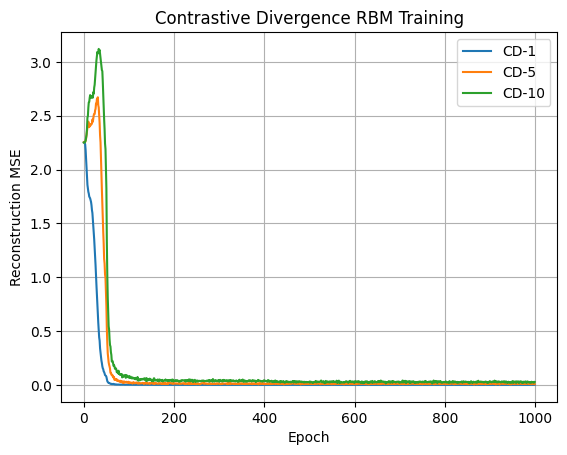

In [26]:
for k, result in cd_results.items():
    plt.plot(result["info"]["recon_mse"], label=f"CD-{k}")

plt.xlabel("Epoch")
plt.ylabel("Reconstruction MSE")
plt.title("Contrastive Divergence RBM Training")
plt.legend()
plt.grid(True)
plt.show()

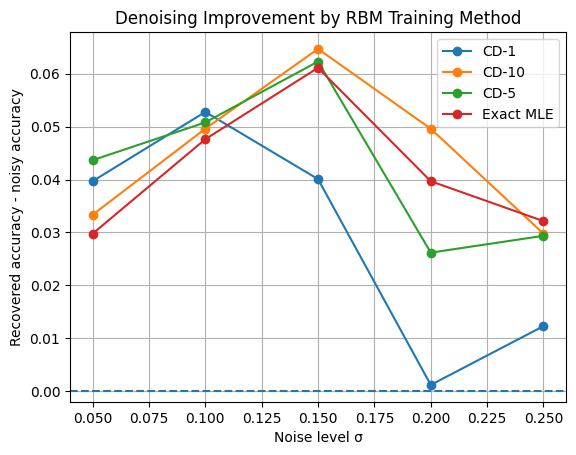

In [27]:
plot_df = summary_compare[summary_compare["rho_mode"] == "robust"]

for method in sorted(plot_df["training_method"].unique()):
    sub = plot_df[plot_df["training_method"] == method]
    plt.plot(
        sub["sigma"],
        sub["improvement"],
        marker="o",
        label=method,
    )

plt.axhline(0.0, linestyle="--")
plt.xlabel("Noise level σ")
plt.ylabel("Recovered accuracy - noisy accuracy")
plt.title("Denoising Improvement by RBM Training Method")
plt.legend()
plt.grid(True)
plt.show()

In [28]:
Q_best_cd = cd_results[10]["Q"]
W_best_cd = cd_results[10]["W"]
bv_best_cd = cd_results[10]["bv"]
bh_best_cd = cd_results[10]["bh"]

diagnostics_cd10 = evaluate_prior(
    Q_best_cd,
    X_unique,
    sigma=0.15,
    n_noise_trials=100,
    seed=rng_seed,
)

Mean free energy:
Clean BAS: -47.85170764567976
Noisy BAS: -41.261153957256795
Random: -36.755114532121375
Clean better than noisy fraction: 0.7721428571428571
Clean better than random fraction: 0.9857142857142858


In [29]:
print("CD-1 Parameters:")
print("W:\n", cd_results[1]["W"])
print("bv:\n", cd_results[1]["bv"])
print("bh:\n", cd_results[1]["bh"])

print("CD-5 Parameters:")
print("W:\n", cd_results[5]["W"])
print("bv:\n", cd_results[5]["bv"])
print("bh:\n", cd_results[5]["bh"])

print("CD-10 Parameters:")
print("W:\n", W_best_cd)
print("bv:\n", bv_best_cd)
print("bh:\n", bh_best_cd)

CD-1 Parameters:
W:
 [[ 0.75925891  1.79175883  3.84041403  1.86405126  3.89206551 -3.85580581
  -1.96859132  3.68703949  1.82605348 -6.0535296 ]
 [ 1.47051905  1.79622595 -1.7743757  -3.64194328  3.97196769 -5.87760037
   3.74136157 -1.92017051  1.91749387 -3.90783493]
 [ 0.36304587 -3.76110171 -1.75713804  1.90482175  6.1871272  -3.78187593
  -1.56232305 -1.66951044 -3.76206987 -3.70409866]
 [ 0.0637381  -4.0154385   6.06047432  1.73201975 -1.93677408  1.716522
   3.80278155  3.79700913  1.6989564  -3.93449901]
 [ 0.73285831 -4.04203841  3.87422167 -3.69214065 -1.71214675 -3.73670285
   6.00296413 -1.90313727  1.85806593  1.89454149]
 [-0.46938474 -6.13672417  3.89724819  1.51932167  3.7068292   1.6191745
   3.97377867 -1.8170416  -3.86446308  1.75084272]
 [ 1.23437234  1.81825252  3.89848715 -3.59454658 -1.78751144  2.07118727
  -1.91731085  5.88471853 -3.84987785 -3.73296644]
 [ 1.8947145   1.82019743 -1.90014764 -5.88663248 -1.91444648 -3.73762101
   3.79412408  3.67426203 -3.8048

## Test on large set

In [30]:
def rho_from_sigma(sigma: float, mode: str = "robust") -> float:
    """
    mode='exact': rho = log((1-sigma)/sigma)
    mode='robust': rho = log((1-0.75*sigma)/(0.75*sigma))
    """
    if mode == "exact":
        sigma_eff = sigma
    elif mode == "robust":
        sigma_eff = 0.75 * sigma
    else:
        raise ValueError("mode must be 'exact' or 'robust'")

    return np.log((1.0 - sigma_eff) / sigma_eff)


def exact_denoise_many_noisy_patterns(
    Q: np.ndarray,
    noisy_patterns: np.ndarray,
    rho: float,
    batch_size: int = 64,
):
    """
    For each noisy visible pattern y, solve

        min_{v,h} E_Q(v,h) + rho * ||v - y||_0

    exactly by brute force over all visible+hidden states.

    This is equivalent to the paper's diagonal-update QUBO objective,
    but avoids rebuilding Q for every noisy image.
    """
    noisy_patterns = np.asarray(noisy_patterns, dtype=np.int8)

    n_total = Q.shape[0]
    n_visible = noisy_patterns.shape[1]

    states = enumerate_binary_states(n_total).astype(np.int8)
    visible_states = states[:, :n_visible]

    base_energies = qubo_energy_upper(Q, states)

    recovered = np.zeros_like(noisy_patterns)
    best_energies = np.zeros(len(noisy_patterns), dtype=float)

    for start in range(0, len(noisy_patterns), batch_size):
        stop = min(start + batch_size, len(noisy_patterns))
        batch = noisy_patterns[start:stop]

        # Hamming distance between every candidate visible state and every noisy pattern.
        distances = np.sum(
            visible_states[:, None, :] != batch[None, :, :],
            axis=2,
        )

        total_energies = base_energies[:, None] + rho * distances
        best_indices = np.argmin(total_energies, axis=0)

        recovered[start:stop] = visible_states[best_indices]
        best_energies[start:stop] = total_energies[best_indices, np.arange(stop - start)]

    return recovered, best_energies


def bootstrap_ci(values, n_boot=1000, seed=0):
    """
    95% bootstrap confidence interval for the mean.
    """
    rng = np.random.default_rng(seed)
    values = np.asarray(values, dtype=float)

    boot_means = []
    for _ in range(n_boot):
        sample = rng.choice(values, size=len(values), replace=True)
        boot_means.append(sample.mean())

    lo, hi = np.percentile(boot_means, [2.5, 97.5])
    return lo, hi

def make_overlap_curve(
    models: dict,
    X_test: np.ndarray,
    sigma_values,
    rho_modes=("exact", "robust"),
    seed: int = 0,
    batch_size: int = 64,
    n_boot: int = 500,
):
    rng = np.random.default_rng(seed)

    rows = []

    for sigma in sigma_values:
        # Use the same noisy test set for every method at this sigma.
        X_noisy = np.array(
            [add_bitflip_noise(x, sigma=sigma, rng=rng) for x in X_test],
            dtype=np.int8,
        )

        noisy_overlap_per_image = np.mean(X_test == X_noisy, axis=1)

        lo, hi = bootstrap_ci(
            noisy_overlap_per_image,
            n_boot=n_boot,
            seed=int(rng.integers(0, 1_000_000)),
        )

        rows.append({
            "method": "Noisy input",
            "model": "None",
            "rho_mode": "none",
            "sigma": sigma,
            "overlap": noisy_overlap_per_image.mean(),
            "ci_low": lo,
            "ci_high": hi,
        })

        # Cache unique noisy patterns because many will repeat.
        unique_noisy, inverse = np.unique(
            X_noisy,
            axis=0,
            return_inverse=True,
        )

        for model_name, Q_model in models.items():
            for rho_mode in rho_modes:
                rho = rho_from_sigma(sigma, mode=rho_mode)

                recovered_unique, best_energies = exact_denoise_many_noisy_patterns(
                    Q_model,
                    unique_noisy,
                    rho=rho,
                    batch_size=batch_size,
                )

                recovered = recovered_unique[inverse]
                overlap_per_image = np.mean(X_test == recovered, axis=1)

                lo, hi = bootstrap_ci(
                    overlap_per_image,
                    n_boot=n_boot,
                    seed=int(rng.integers(0, 1_000_000)),
                )

                rows.append({
                    "method": f"{model_name}, {rho_mode} rho",
                    "model": model_name,
                    "rho_mode": rho_mode,
                    "sigma": sigma,
                    "overlap": overlap_per_image.mean(),
                    "ci_low": lo,
                    "ci_high": hi,
                })

    return pd.DataFrame(rows)

In [31]:
n_test = 100

X_test = sample_bars_and_stripes(
    n=n_side,
    n_samples=n_test,
    rng=rng,
)

sigma_values = np.arange(0.025, 0.301, 0.025)

Q_cd10_test = cd_results[10]["Q"]
Q_e_test = Q_e

models = {
    "CD-10": Q_cd10_test,
    "Exact MLE": Q_e_test,
}

In [32]:
overlap_df = make_overlap_curve(
    models=models,
    X_test=X_test,
    sigma_values=sigma_values,
    rho_modes=("exact", "robust"),
    seed=rng_seed,
    batch_size=64,
    n_boot=500,
)

overlap_df.head()

,method,model,rho_mode,sigma,overlap,ci_low,ci_high
0,Noisy input,None,none,0.025,0.976667,0.964444,0.98725
1,"CD-10, exact rho",CD-10,exact,0.025,0.992222,0.980000,1.00000
2,"CD-10, robust rho",CD-10,robust,0.025,0.992222,0.980000,1.00000
3,"Exact MLE, exact rho",Exact MLE,exact,0.025,0.992222,0.981111,1.00000
4,"Exact MLE, robust rho",Exact MLE,robust,0.025,0.992222,0.981111,1.00000


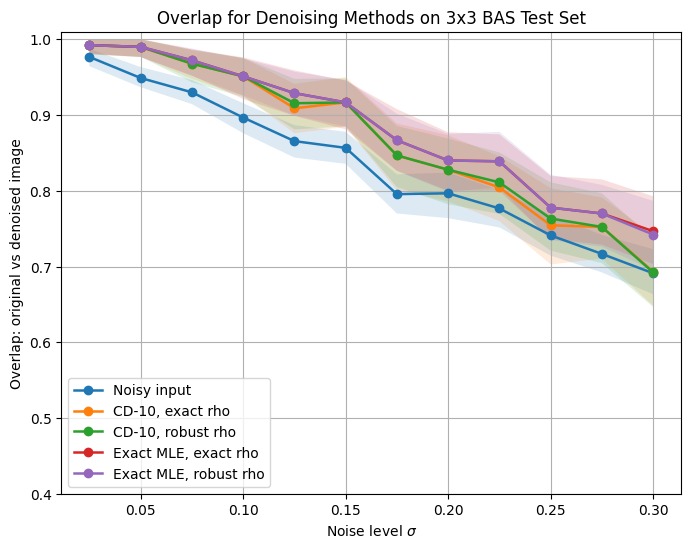

In [33]:
plt.figure(figsize=(8, 6))

for method in overlap_df["method"].unique():
    sub = overlap_df[overlap_df["method"] == method].sort_values("sigma")

    plt.plot(
        sub["sigma"],
        sub["overlap"],
        marker="o",
        linewidth=1.8,
        label=method,
    )

    plt.fill_between(
        sub["sigma"],
        sub["ci_low"],
        sub["ci_high"],
        alpha=0.15,
    )

plt.xlabel("Noise level $\\sigma$")
plt.ylabel("Overlap: original vs denoised image")
plt.title(f"Overlap for Denoising Methods on {n_side}x{n_side} BAS Test Set")
plt.ylim(0.4, 1.01)
plt.grid(True)
plt.legend()
plt.show()

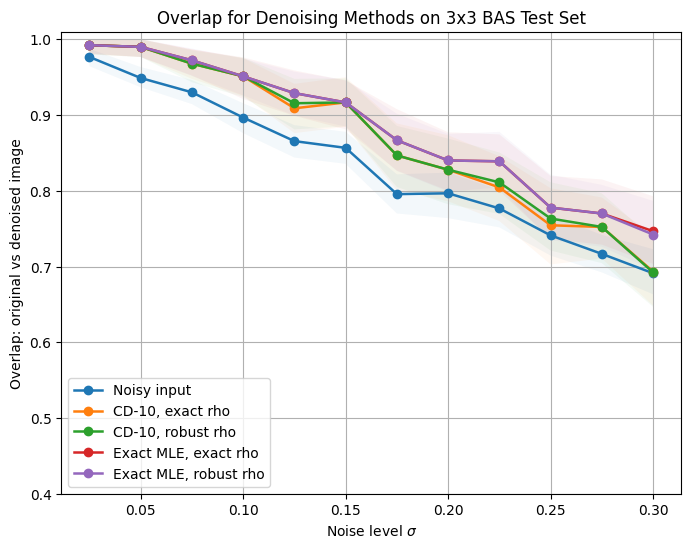

In [34]:
plt.figure(figsize=(8, 6))

for method in overlap_df["method"].unique():
    sub = overlap_df[overlap_df["method"] == method].sort_values("sigma")

    plt.plot(
        sub["sigma"],
        sub["overlap"],
        marker="o",
        linewidth=1.8,
        label=method,
    )

    plt.fill_between(
        sub["sigma"],
        sub["ci_low"],
        sub["ci_high"],
        alpha=0.05,
    )

plt.xlabel("Noise level $\\sigma$")
plt.ylabel("Overlap: original vs denoised image")
plt.title(f"Overlap for Denoising Methods on {n_side}x{n_side} BAS Test Set")
plt.ylim(0.4, 1.01)
plt.grid(True)
plt.legend()
plt.show()

## Initial Qiskit Approach

In [35]:
import re

from collections import Counter

from qiskit.circuit.library import QAOAAnsatz
from qiskit.quantum_info import SparsePauliOp

from qiskit_aer.primitives import EstimatorV2 as AerEstimator
from qiskit_aer.primitives import SamplerV2 as AerSampler

from scipy.optimize import minimize
from tqdm.auto import tqdm

f:\Personal\PhD\portfolio\q-img-denoise\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [36]:
def rbm_denoising_to_ising(W, bv, bh, noisy_visible, rho, include_penalty_constant=False):
    """
    Directly convert the RBM denoising objective to Ising coefficients.

    If include_penalty_constant=False, the returned constant matches the
    modified-QUBO objective used by apply_denoising_diagonal_update.

    If include_penalty_constant=True, the returned constant matches the full
    penalized objective:
        E(v,h) + rho * sum_i (v_i - noisy_i)^2.
    """
    W = np.asarray(W, dtype=float)
    bv = np.asarray(bv, dtype=float)
    bh = np.asarray(bh, dtype=float)
    noisy_visible = np.asarray(noisy_visible, dtype=int)

    n_visible, n_hidden = W.shape
    n_total = n_visible + n_hidden

    bv_tilde = bv + rho * (1 - 2 * noisy_visible)

    h_ising = np.zeros(n_total, dtype=float)
    J_ising = np.zeros((n_total, n_total), dtype=float)

    h_ising[:n_visible] = (
        -0.5 * bv_tilde
        -0.25 * np.sum(W, axis=1)
    )

    h_ising[n_visible:] = (
        -0.5 * bh
        -0.25 * np.sum(W, axis=0)
    )

    for i in range(n_visible):
        for j in range(n_hidden):
            J_ising[i, n_visible + j] = 0.25 * W[i, j]

    # Constant matching the modified-QUBO objective.
    const = (
        0.5 * np.sum(bv_tilde)
        + 0.5 * np.sum(bh)
        + 0.25 * np.sum(W)
    )

    # Optional full-penalty constant.
    if include_penalty_constant:
        const += rho * np.sum(noisy_visible)

    return const, h_ising, J_ising

def ising_to_sparse_pauli_op(h: np.ndarray, J: np.ndarray) -> SparsePauliOp:
    """
    Build SparsePauliOp for

        H = sum_i h_i Z_i + sum_{i<j} J_ij Z_i Z_j.

    Qiskit Pauli strings are big-endian:
    rightmost character acts on qubit 0.
    """
    n = len(h)
    terms = []

    for i, coeff in enumerate(h):
        if abs(coeff) > 1e-12:
            label = ["I"] * n
            label[n - 1 - i] = "Z"
            terms.append(("".join(label), float(coeff)))

    for i in range(n):
        for j in range(i + 1, n):
            coeff = J[i, j]
            if abs(coeff) > 1e-12:
                label = ["I"] * n
                label[n - 1 - i] = "Z"
                label[n - 1 - j] = "Z"
                terms.append(("".join(label), float(coeff)))

    if not terms:
        return SparsePauliOp.from_list([("I" * n, 0.0)])

    return SparsePauliOp.from_list(terms).simplify()

def _parameter_index(param_name: str) -> int:
    """
    Extract the index from names like beta[0], gamma[1], gamma[2].
    """
    match = re.search(r"\[(\d+)\]", param_name)
    if match is None:
        raise ValueError(f"Could not parse parameter index from {param_name}")
    return int(match.group(1))

Although the original denoising paper presents the RBM objective as a QUBO for quantum annealing, the same trained RBM parameters can be mapped directly to an Ising Hamiltonian for gate-model QAOA. We used the QUBO formulation to verify the mapping against the paper’s denoising objective, then construct the Qiskit cost operator directly from the RBM-derived Ising coefficients.

In [37]:
# Best CD-10 model
W_model = W_best_cd
bv_model = bv_best_cd
bh_model = bh_best_cd

Q_model = rbm_to_qubo_upper(W_model, bv_model, bh_model)

n_visible = len(bv_model)
n_total = Q_model.shape[0]
n_hidden = n_total - n_visible

print("n_visible:", n_visible)
print("n_hidden:", n_hidden)
print("n_qubits for QAOA:", n_total)

n_visible: 9
n_hidden: 10
n_qubits for QAOA: 19


In [38]:
noisy_visible.reshape(n_side, n_side)

array([[1, 0, 0],
       [1, 1, 1],
       [0, 1, 0]])

## Qiskit Aer Simulations

In [39]:
def qaoa_parameter_values(ansatz, gammas, betas):
    """
    Return parameter values in the order expected by ansatz.parameters.

    QAOAAnsatz parameter names are usually β[0], β[1], ..., γ[0], γ[1], ...
    but this function does not assume the order.
    """
    values = []

    for param in ansatz.parameters:
        name = param.name

        if name.startswith("γ") or name.lower().startswith("gamma"):
            idx = _parameter_index(name)
            values.append(float(gammas[idx]))

        elif name.startswith("β") or name.lower().startswith("beta"):
            idx = _parameter_index(name)
            values.append(float(betas[idx]))

        else:
            raise ValueError(
                f"Unrecognized QAOA parameter name: {name}. "
                f"All parameters: {[p.name for p in ansatz.parameters]}"
            )

    return values

def build_qaoa_ansatz_from_rbm_for_aer(
    W,
    bv,
    bh,
    noisy_visible,
    rho,
    reps=1,
):
    """
    Build QAOAAnsatz and SparsePauliOp directly from the RBM denoising Ising model.
    """
    const, h_ising, J_ising = rbm_denoising_to_ising(
        W=W,
        bv=bv,
        bh=bh,
        noisy_visible=noisy_visible,
        rho=rho,
        include_penalty_constant=False,
    )

    cost_op = ising_to_sparse_pauli_op(h_ising, J_ising)
    # Used by AerEstimator.
    observable_op = ising_to_sparse_pauli_op(h_ising, J_ising)

    ansatz = QAOAAnsatz(
        cost_operator=cost_op,
        reps=reps,
        flatten=True,
    )

    return ansatz, cost_op, observable_op, h_ising, J_ising, const

def qaoa_aer_estimator_expectation(
    params,
    ansatz,
    observable_op,
    reps,
    estimator,
):
    """
    Evaluate QAOA energy using qiskit-aer EstimatorV2.
    """
    gammas = params[:reps]
    betas = params[reps:]

    parameter_values = qaoa_parameter_values(ansatz, gammas, betas)

    pub = (
        ansatz,
        observable_op,
        np.asarray([parameter_values], dtype=float),
    )

    job = estimator.run([pub])
    result = job.result()
    pub_result = result[0]

    ev = np.asarray(pub_result.data.evs).reshape(-1)[0]
    return float(ev)

def optimize_aer_estimator_qaoa_for_denoising_instance(
    W,
    bv,
    bh,
    noisy_visible,
    rho,
    reps=1,
    n_starts=8,
    seed=0,
    maxiter=250,
    initial_points=None,
    estimator_options=None,
):
    """
    Optimize QAOA angles using qiskit-aer EstimatorV2.
    """
    rng = np.random.default_rng(seed)

    ansatz, cost_op, observable_op, h_ising, J_ising, const = build_qaoa_ansatz_from_rbm_for_aer(
        W=W,
        bv=bv,
        bh=bh,
        noisy_visible=noisy_visible,
        rho=rho,
        reps=reps,
    )

    if estimator_options is None:
        estimator_options = {
            "default_precision": 0.0,
            "backend_options": {
                "method": "statevector",
            },
        }

    estimator = AerEstimator(options=estimator_options)

    bounds = [(-np.pi, np.pi)] * reps + [(0.0, np.pi / 2)] * reps

    start_points = []

    if initial_points is not None:
        for point in initial_points:
            point = np.asarray(point, dtype=float)
            if point.shape != (2 * reps,):
                raise ValueError(
                    f"Initial point has shape {point.shape}, expected {(2 * reps,)}"
                )
            start_points.append(point)

    for _ in range(n_starts):
        x0 = np.concatenate([
            rng.uniform(-np.pi, np.pi, size=reps),
            rng.uniform(0.0, np.pi / 2, size=reps),
        ])
        start_points.append(x0)

    best_result = None

    for x0 in start_points:
        result = minimize(
            qaoa_aer_estimator_expectation,
            x0=x0,
            args=(ansatz, observable_op, reps, estimator),
            method="L-BFGS-B",
            bounds=bounds,
            options={"maxiter": maxiter},
        )

        if best_result is None or result.fun < best_result.fun:
            best_result = result

    gammas = best_result.x[:reps]
    betas = best_result.x[reps:]
    parameter_values = qaoa_parameter_values(ansatz, gammas, betas)

    final_estimator_energy = qaoa_aer_estimator_expectation(
        best_result.x,
        ansatz,
        observable_op,
        reps,
        estimator,
    )

    return {
        "reps": reps,
        "ansatz": ansatz,
        "cost_op": cost_op,
        "observable_op": observable_op,
        "const": const,
        "h_ising": h_ising,
        "J_ising": J_ising,
        "params": best_result.x,
        "gammas": gammas,
        "betas": betas,
        "parameter_values": parameter_values,
        "optimizer_energy": float(best_result.fun),
        "estimator_energy": float(final_estimator_energy),
        "optimizer_success": best_result.success,
        "optimizer_message": best_result.message,
        "estimator_options": estimator_options,
    }

def visible_key_from_array(x):
    return "".join(str(int(b)) for b in x)


def visible_array_from_key(key):
    return np.array([int(c) for c in key], dtype=int)


def sample_visible_outputs_with_aer_sampler(
    qaoa_result,
    n_visible,
    shots=2048,
    seed=0,
    sampler_options=None,
    clean_visible=None,
):
    """
    Sample optimized QAOA circuit using qiskit-aer SamplerV2.

    No Hamiltonian scoring is performed.

    Outputs:
      - raw bitstring counts
      - visible-only counts
      - most frequent visible image
      - pixel-wise majority visible image
      - optional overlap metrics if clean_visible is provided
    """
    if sampler_options is None:
        sampler_options = {
            "backend_options": {
                "method": "statevector",
            }
        }

    sampler = AerSampler(
        default_shots=shots,
        seed=seed,
        options=sampler_options,
    )

    ansatz = qaoa_result["ansatz"]
    parameter_values = qaoa_result["parameter_values"]

    measured = ansatz.copy()
    measured.measure_all()

    pub = (
        measured,
        np.asarray([parameter_values], dtype=float),
        shots,
    )

    job = sampler.run([pub])
    result = job.result()
    pub_result = result[0]

    data = pub_result.data

    # measure_all() usually creates "meas".
    # If this fails, print(data) and inspect the register name.
    bitarray = getattr(data, "meas")
    counts = bitarray.get_counts()

    visible_counts = Counter()
    visible_sum = np.zeros(n_visible, dtype=float)
    total_shots = 0

    expected_overlap = None
    overlap_sum = 0.0

    if clean_visible is not None:
        clean_visible = np.asarray(clean_visible, dtype=int)

    for bitstring, count in counts.items():
        total_shots += count

        # Qiskit bitstring order is q_{n-1}...q_0.
        # Our internal convention is [q_0, q_1, ..., q_{n-1}].
        x_full = np.array([int(c) for c in bitstring[::-1]], dtype=int)

        visible = x_full[:n_visible]
        key = visible_key_from_array(visible)

        visible_counts[key] += count
        visible_sum += count * visible

        if clean_visible is not None:
            overlap_sum += count * overlap_accuracy(clean_visible, visible)

    visible_means = visible_sum / total_shots
    majority_visible = (visible_means >= 0.5).astype(int)

    most_frequent_key, most_frequent_count = visible_counts.most_common(1)[0]
    most_frequent_visible = visible_array_from_key(most_frequent_key)

    output = {
        "shots": shots,
        "counts": counts,
        "visible_counts": dict(visible_counts),
        "visible_means": visible_means,
        "majority_visible": majority_visible,
        "most_frequent_visible": most_frequent_visible,
        "most_frequent_visible_count": most_frequent_count,
        "most_frequent_visible_probability": most_frequent_count / total_shots,
    }

    if clean_visible is not None:
        expected_overlap = overlap_sum / total_shots

        output.update({
            "expected_overlap_from_samples": expected_overlap,
            "majority_overlap": overlap_accuracy(clean_visible, majority_visible),
            "most_frequent_overlap": overlap_accuracy(clean_visible, most_frequent_visible),
            "prob_perfect_visible": sum(
                count
                for key, count in visible_counts.items()
                if np.array_equal(visible_array_from_key(key), clean_visible)
            ) / total_shots,
        })

    return output

In [40]:
print(noisy_visible.reshape(n_side, n_side))

[[1 0 0]
 [1 1 1]
 [0 1 0]]


In [41]:
qaoa_p2_aer = optimize_aer_estimator_qaoa_for_denoising_instance(
    W=W_model,
    bv=bv_model,
    bh=bh_model,
    noisy_visible=noisy_visible,
    rho=rho,
    reps=2,
    n_starts=16,
    seed=rng_seed,
    maxiter=3000,
    initial_points=None,
)

In [42]:
def ising_energy_of_bitstring(x, const, h, J):
    """
    Compute Ising energy for a single binary bitstring x in {0,1}^n using

        z_i = 1 - 2 x_i

    and

        E(z) = const + sum_i h_i z_i + sum_{i<j} J_ij z_i z_j
    """
    x = np.asarray(x, dtype=int)
    z = 1 - 2 * x

    energy = float(const + np.dot(h, z))

    n = len(x)
    for i in range(n):
        for j in range(i + 1, n):
            if abs(J[i, j]) > 1e-12:
                energy += float(J[i, j] * z[i] * z[j])

    return energy

def sample_best_with_aer_sampler(
    qaoa_result,
    shots=2048,
    seed=0,
    sampler_options=None,
):
    """
    Sample optimized QAOA circuit using AerSampler, then score every sampled
    bitstring with the Ising Hamiltonian and keep the best observed one.
    """
    if sampler_options is None:
        sampler_options = {
            "backend_options": {
                "method": "statevector",
            }
        }

    sampler = AerSampler(
        default_shots=shots,
        seed=seed,
        options=sampler_options,
    )

    ansatz = qaoa_result["ansatz"]
    parameter_values = qaoa_result["parameter_values"]

    measured = ansatz.copy()
    measured.measure_all()

    pub = (
        measured,
        np.asarray([parameter_values], dtype=float),
        shots,
    )

    job = sampler.run([pub])
    result = job.result()
    pub_result = result[0]

    data = pub_result.data
    if hasattr(data, "meas"):
        bitarray = data.meas
    else:
        raise RuntimeError(f"Could not find measurement register in sampler result: {data}")

    counts = bitarray.get_counts()

    const = qaoa_result["const"]
    h = qaoa_result["h_ising"]
    J = qaoa_result["J_ising"]

    best_state = None
    best_energy = np.inf
    weighted_energy_sum = 0.0
    total_shots = 0

    for bitstring, count in counts.items():
        # Qiskit returns q_{n-1} ... q_0, reverse to [q_0, ..., q_{n-1}]
        x = np.array([int(c) for c in bitstring[::-1]], dtype=int)

        energy = ising_energy_of_bitstring(x, const, h, J)

        total_shots += count
        weighted_energy_sum += count * energy

        if energy < best_energy:
            best_energy = energy
            best_state = x.copy()

    return {
        "counts": counts,
        "best_sample_state": best_state,
        "best_sample_energy": float(best_energy),
        "mean_sample_energy": float(weighted_energy_sum / total_shots),
        "shots": total_shots,
    }

def qaoa_denoise_single_instance(
    clean_visible,
    W,
    bv,
    bh,
    sigma,
    rho,
    reps=2,
    shots=2048,
    seed=0,
):
    rng = np.random.default_rng(seed)

    noisy_visible = add_bitflip_noise(clean_visible, sigma=sigma, rng=rng)

    # QAOA
    qaoa_result = optimize_aer_estimator_qaoa_for_denoising_instance(
        W=W,
        bv=bv,
        bh=bh,
        noisy_visible=noisy_visible,
        rho=rho,
        reps=reps,
        n_starts=16,
        seed=seed,
        maxiter=3000,
    )

    sampled = sample_best_with_aer_sampler(
        qaoa_result,
        shots=shots,
        seed=seed,
    )
    qaoa_visible = sampled["best_sample_state"][:len(clean_visible)]

    return {
        "clean_visible": clean_visible,
        "noisy_visible": noisy_visible,
        "qaoa_visible": qaoa_visible,
        "noisy_overlap": overlap_accuracy(clean_visible, noisy_visible),
        "qaoa_overlap": overlap_accuracy(clean_visible, qaoa_visible),
        "estimator_energy": qaoa_result["estimator_energy"],
        "best_sample_energy": sampled["best_sample_energy"],
    }

def benchmark_qaoa_vs_sigma(
    X_test,
    W,
    bv,
    bh,
    sigmas,
    rho_mode="robust",
    reps=2,
    shots=2048,
    n_test=100,
    seed=0,
):
    rng = np.random.default_rng(seed)

    n_test = min(n_test, len(X_test))

    test_indices = rng.choice(len(X_test), size=n_test, replace=False)

    rows = []

    for sigma in sigmas:
        rho = rho_from_sigma(sigma, mode=rho_mode)

        for k, idx in enumerate(tqdm(test_indices, desc=f"sigma={sigma:.2f}")):
            clean_visible = X_test[idx]

            result = qaoa_denoise_single_instance(
                clean_visible=clean_visible,
                W=W,
                bv=bv,
                bh=bh,
                sigma=sigma,
                rho=rho,
                reps=reps,
                shots=shots,
                seed=seed + 1000 * int(100 * sigma) + k,
            )

            rows.append({
                "sigma": sigma,
                "rho_mode": rho_mode,
                "reps": reps,
                "test_idx": int(idx),
                "noisy_overlap": result["noisy_overlap"],
                "qaoa_overlap": result["qaoa_overlap"],
                "estimator_energy": result["estimator_energy"],
                "best_sample_energy": result["best_sample_energy"],
            })

    return pd.DataFrame(rows)

def summarize_qaoa_benchmark(df):
    summary = (
        df.groupby(["sigma", "rho_mode", "reps"], as_index=False)
        .agg(
            noisy_overlap_mean=("noisy_overlap", "mean"),
            noisy_overlap_std=("noisy_overlap", "std"),
            qaoa_overlap_mean=("qaoa_overlap", "mean"),
            qaoa_overlap_std=("qaoa_overlap", "std"),
            n=("qaoa_overlap", "count"),
        )
    )

    summary["noisy_overlap_ci95"] = 1.96 * summary["noisy_overlap_std"] / np.sqrt(summary["n"])
    summary["qaoa_overlap_ci95"] = 1.96 * summary["qaoa_overlap_std"] / np.sqrt(summary["n"])

    return summary

def plot_qaoa_overlap_vs_sigma(summary_df, title=None):
    plt.figure(figsize=(8, 6))

    x = summary_df["sigma"].values

    noisy_line = plt.plot(x, summary_df["noisy_overlap_mean"].values, marker="o", label="Noisy input")
    qaoa_line = plt.plot(x, summary_df["qaoa_overlap_mean"].values, marker="^", label="QAOA denoising")

    plt.fill_between(
        x,
        summary_df["qaoa_overlap_mean"] - summary_df["qaoa_overlap_ci95"],
        summary_df["qaoa_overlap_mean"] + summary_df["qaoa_overlap_ci95"],
        color=qaoa_line[0].get_color(),
        alpha=0.15,
        # label="QAOA 95% CI",
    )

    plt.fill_between(
        x,
        summary_df["noisy_overlap_mean"] - summary_df["noisy_overlap_ci95"],
        summary_df["noisy_overlap_mean"] + summary_df["noisy_overlap_ci95"],
        color=noisy_line[0].get_color(),
        alpha=0.15,
        # label="Noisy 95% CI",
    )

    plt.xlabel("Noise level σ")
    plt.ylabel("Overlap: original vs. denoised image")
    if title is not None:
        plt.title(title)
    plt.ylim(0.0, 1.05)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [43]:
sigmas = [0.05, 0.10, 0.15, 0.20, 0.25]

df_qaoa = benchmark_qaoa_vs_sigma(
    X_test=X_test,
    W=W_model,
    bv=bv_model,
    bh=bh_model,
    sigmas=sigmas,
    rho_mode="robust",
    reps=2,
    shots=2048,
    n_test=10,
    seed=rng_seed,
)

# summary_qaoa = summarize_qaoa_benchmark(df_qaoa)
# summary_qaoa

sigma=0.25: 100%|██████████| 10/10 [20:55<00:00, 125.57s/it]


In [44]:
summary_qaoa = summarize_qaoa_benchmark(df_qaoa)
summary_qaoa

,sigma,rho_mode,reps,noisy_overlap_mean,noisy_overlap_std,qaoa_overlap_mean,qaoa_overlap_std,n,noisy_overlap_ci95,qaoa_overlap_ci95
0,0.05,robust,2,0.955556,0.077690,1.000000,0.000000,10,0.048152,0.000000
1,0.10,robust,2,0.911111,0.087646,0.966667,0.105409,10,0.054323,0.065333
2,0.15,robust,2,0.844444,0.107344,0.933333,0.140546,10,0.066532,0.087111
3,0.20,robust,2,0.855556,0.117706,0.911111,0.194577,10,0.072955,0.120600
4,0.25,robust,2,0.777778,0.104757,0.811111,0.209840,10,0.064929,0.130060


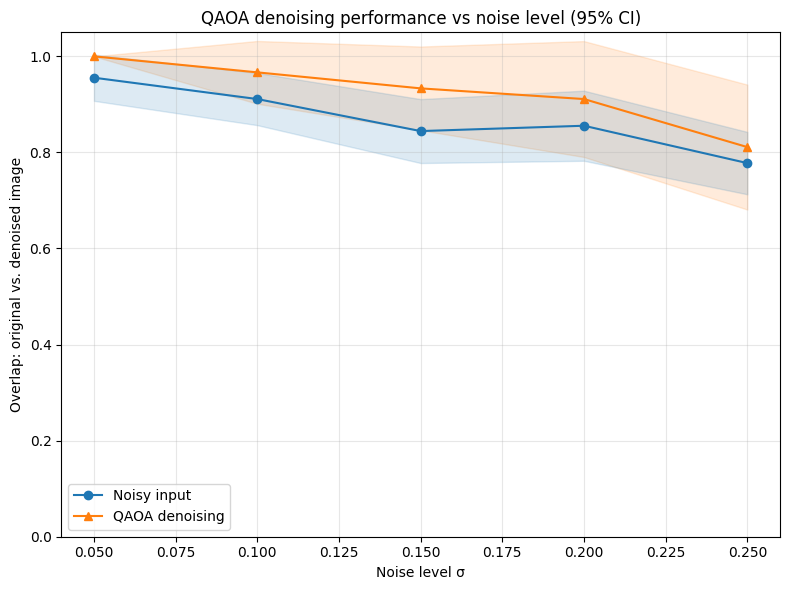

In [45]:
plot_qaoa_overlap_vs_sigma(
    summary_qaoa,
    title="QAOA denoising performance vs noise level (95% CI)"
)

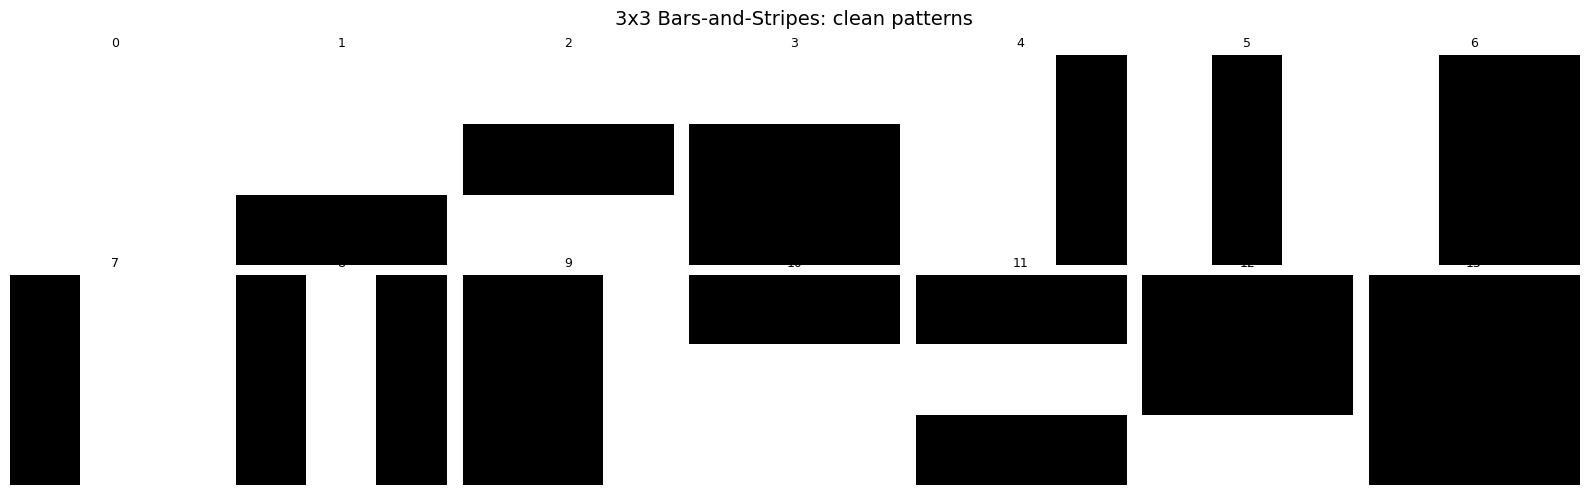

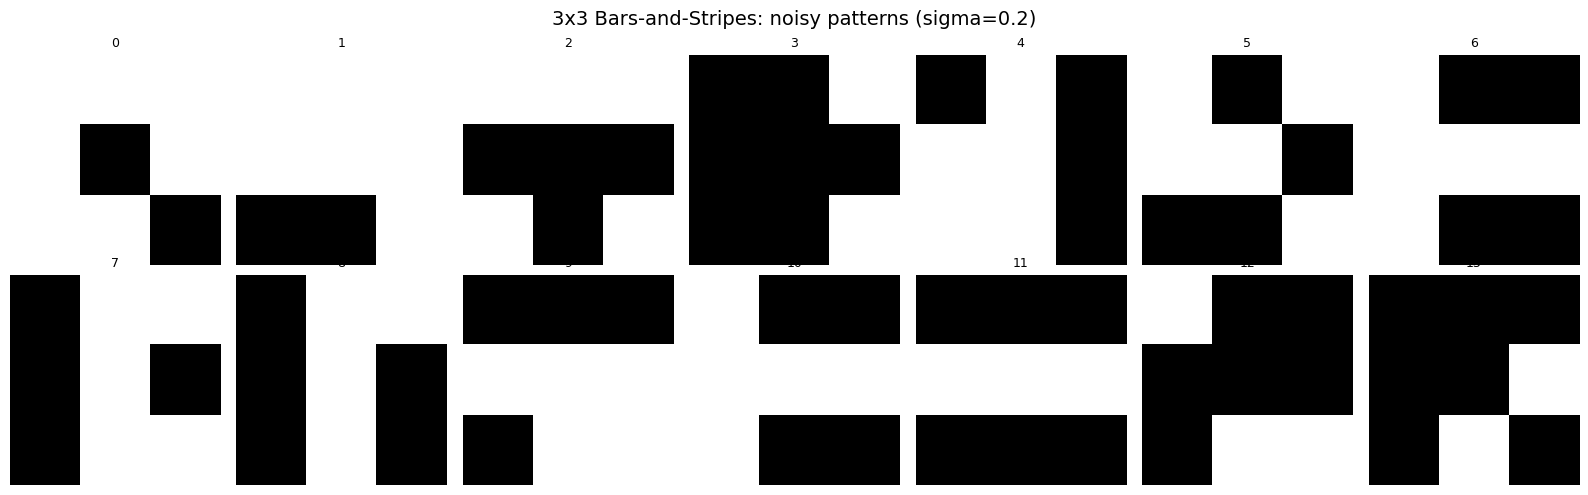

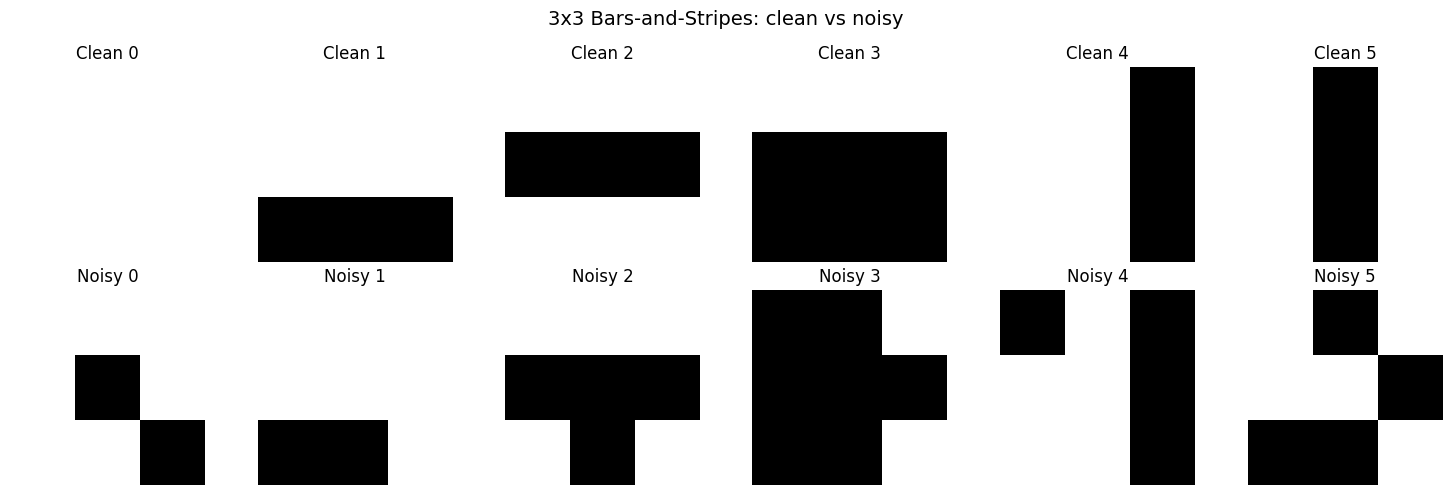

In [46]:
# 3x3 Bars-and-Stripes examples: clean and noisy

bas = X_unique if "X_unique" in globals() else make_bars_and_stripes(3)
n_side = 3
rng_plot = np.random.default_rng(42)

def plot_image_grid(images, title, ncols=7, figsize=(14, 5), cmap="gray_r"):
    n = len(images)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.atleast_1d(axes).ravel()

    for ax in axes:
        ax.axis("off")

    for i, img in enumerate(images):
        axes[i].imshow(img.reshape(n_side, n_side), cmap=cmap, vmin=0, vmax=1)
        axes[i].set_title(f"{i}", fontsize=9)
        axes[i].axis("off")

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

# Clean BAS gallery
plot_image_grid(
    bas,
    title="3x3 Bars-and-Stripes: clean patterns",
    ncols=7,
    figsize=(16, 5),
)

# Noisy BAS gallery
sigma_demo = 0.20
bas_noisy = np.array([add_bitflip_noise(img, sigma=sigma_demo, rng=rng_plot) for img in bas], dtype=int)

plot_image_grid(
    bas_noisy,
    title=f"3x3 Bars-and-Stripes: noisy patterns (sigma={sigma_demo})",
    ncols=7,
    figsize=(16, 5),
)

# Side-by-side clean vs noisy examples
n_examples = min(6, len(bas))
fig, axes = plt.subplots(2, n_examples, figsize=(2.5 * n_examples, 5))

for i in range(n_examples):
    axes[0, i].imshow(bas[i].reshape(n_side, n_side), cmap="gray_r", vmin=0, vmax=1)
    axes[0, i].set_title(f"Clean {i}")
    axes[0, i].axis("off")

    axes[1, i].imshow(bas_noisy[i].reshape(n_side, n_side), cmap="gray_r", vmin=0, vmax=1)
    axes[1, i].set_title(f"Noisy {i}")
    axes[1, i].axis("off")

fig.suptitle("3x3 Bars-and-Stripes: clean vs noisy", fontsize=14)
plt.tight_layout()
plt.show()

## Aer and optional IBM Quantum hardware

Run the notebook with the working directory set to `q-img-denoise`. The default runs locally with Aer. To submit IBM Quantum jobs, put your API key and instance CRN in `.env` and set `RUN_HARDWARE = True` below. The report PDF contains the original hardware results.

In [47]:
# add your IBM Quantum credentials to the .env file in the project root
# and set RUN_HARDWARE = True to run on IBM Quantum.
# e.g.,
# QISKIT_IBM_CHANNEL=ibm_quantum_platform
# QISKIT_IBM_TOKEN=123123123123123123
# QISKIT_IBM_INSTANCE=456456456456456456

RUN_HARDWARE = False

if RUN_HARDWARE:
    import os
    from pathlib import Path

    from dotenv import load_dotenv
    from qiskit.transpiler import generate_preset_pass_manager
    from qiskit_ibm_runtime import QiskitRuntimeService
    from qiskit_ibm_runtime import SamplerV2 as RuntimeSampler

    load_dotenv(Path.cwd() / ".env")
    token = os.getenv("QISKIT_IBM_TOKEN", "").strip()
    instance = os.getenv("QISKIT_IBM_INSTANCE", "").strip()
    if not token or not instance:
        raise RuntimeError(
            "Set QISKIT_IBM_TOKEN and QISKIT_IBM_INSTANCE in .env before running hardware."
        )

    service = QiskitRuntimeService(
        channel=os.getenv("QISKIT_IBM_CHANNEL", "ibm_quantum_platform"),
        token=token,
        instance=instance,
    )

In [48]:
def bind_qaoa_result_to_measured_circuit(qaoa_result):
    ansatz = qaoa_result["ansatz"]
    parameter_values = qaoa_result["parameter_values"]

    bound = ansatz.assign_parameters(
        dict(zip(ansatz.parameters, parameter_values))
    )

    measured = bound.copy()
    measured.measure_all()

    return measured

In [49]:
if RUN_HARDWARE:
    # Use the QAOA result optimized locally with AerEstimator.
    qaoa_result = qaoa_p2_aer

    n_qubits = qaoa_result["ansatz"].num_qubits
    print("Qubits:", n_qubits)
    print("Circuit depth before transpilation:", qaoa_result["ansatz"].depth())
    print("2-qubit gates before transpilation:", qaoa_result["ansatz"].num_nonlocal_gates())

In [50]:
if RUN_HARDWARE:
    qc_bound_measured = bind_qaoa_result_to_measured_circuit(qaoa_result)

    print("Untranspiled measured circuit depth:", qc_bound_measured.depth())
    print("Untranspiled measured 2-qubit ops:", qc_bound_measured.num_nonlocal_gates())

In [51]:
if RUN_HARDWARE:
    qaoa_p1_aer = optimize_aer_estimator_qaoa_for_denoising_instance(
        W=W_model,
        bv=bv_model,
        bh=bh_model,
        noisy_visible=noisy_visible,
        rho=rho,
        reps=1,
        n_starts=16,
        seed=rng_seed,
        maxiter=1000,
        initial_points=None,
    )

In [52]:
if RUN_HARDWARE:
    qaoa_result = qaoa_p1_aer

    n_qubits = qaoa_result["ansatz"].num_qubits
    print("Qubits:", n_qubits)
    print("Circuit depth before transpilation:", qaoa_result["ansatz"].depth())
    print("2-qubit gates before transpilation:", qaoa_result["ansatz"].num_nonlocal_gates())

    qc_bound_measured = bind_qaoa_result_to_measured_circuit(qaoa_result)

    print("Untranspiled measured circuit depth:", qc_bound_measured.depth())
    print("Untranspiled measured 2-qubit ops:", qc_bound_measured.num_nonlocal_gates())

In [53]:
if RUN_HARDWARE:
    backend = service.least_busy(
        operational=True,
        simulator=False,
        min_num_qubits=n_qubits,
    )

    print("Selected backend:", backend.name)
    print("Backend qubits:", backend.num_qubits)

In [54]:
if RUN_HARDWARE:
    pm = generate_preset_pass_manager(
        backend=backend,
        optimization_level=3,
    )

    qc_isa = pm.run(qc_bound_measured)

    print("Transpiled depth:", qc_isa.depth())
    print("Transpiled 2-qubit ops:", qc_isa.num_nonlocal_gates())
    print("Transpiled qubits:", qc_isa.num_qubits)

In [55]:
if RUN_HARDWARE:
    sampler = RuntimeSampler(mode=backend)

    shots = 2048
    job = sampler.run([qc_isa], shots=shots)

    print("Job ID:", job.job_id())
    print("Backend:", backend.name)

In [56]:
if RUN_HARDWARE:
    result = job.result()
    pub_result = result[0]

    data = pub_result.data
    print(data)

In [57]:
def best_scored_sample_from_counts(counts, qaoa_result, n_visible, clean_visible=None):
    const = qaoa_result["const"]
    h = qaoa_result["h_ising"]
    J = qaoa_result["J_ising"]

    best_state = None
    best_energy = np.inf
    total_shots = 0

    visible_counts = {}
    weighted_overlap = 0.0

    for bitstring, count in counts.items():
        total_shots += count

        # Qiskit bitstring order is q_{n-1}...q_0.
        x_full = np.array([int(c) for c in bitstring[::-1]], dtype=int)
        visible = x_full[:n_visible]

        energy = ising_energy_of_bitstring(x_full, const, h, J)

        key = "".join(str(int(b)) for b in visible)
        visible_counts[key] = visible_counts.get(key, 0) + count

        if clean_visible is not None:
            weighted_overlap += count * overlap_accuracy(clean_visible, visible)

        if energy < best_energy:
            best_energy = energy
            best_state = x_full.copy()

    best_visible = best_state[:n_visible]

    out = {
        "best_state": best_state,
        "best_visible": best_visible,
        "best_energy": best_energy,
        "visible_counts": visible_counts,
    }

    if clean_visible is not None:
        out["expected_visible_overlap"] = weighted_overlap / total_shots
        out["best_visible_overlap"] = overlap_accuracy(clean_visible, best_visible)

    return out

def get_counts_from_sampler_pub_result(pub_result):
    """
    Extract counts from a Runtime/Aer SamplerV2 pub result.
    """
    data = pub_result.data

    if hasattr(data, "meas"):
        return data.meas.get_counts()

    # Fallback: inspect available registers.
    if hasattr(data, "keys"):
        keys = list(data.keys())
        if not keys:
            raise RuntimeError("Sampler result has no classical register data.")
        return getattr(data, keys[0]).get_counts()

    raise RuntimeError(f"Could not extract counts. Inspect pub_result.data: {data}")

def lift_qaoa_params(old_params, old_reps, new_reps):
    """
    Lift QAOA params from old_reps to new_reps by padding extra layers
    with gamma=0, beta=0.

    old_params layout:
        [gamma_0, ..., gamma_{p-1}, beta_0, ..., beta_{p-1}]

    new_params layout:
        [gamma_0, ..., gamma_{P-1}, beta_0, ..., beta_{P-1}]
    """
    if new_reps < old_reps:
        raise ValueError("new_reps must be >= old_reps")

    old_gammas = old_params[:old_reps]
    old_betas = old_params[old_reps:]

    new_gammas = np.zeros(new_reps)
    new_betas = np.zeros(new_reps)

    new_gammas[:old_reps] = old_gammas
    new_betas[:old_reps] = old_betas

    return np.concatenate([new_gammas, new_betas])

def optimize_qaoa_for_hardware_instance(
    W,
    bv,
    bh,
    noisy_visible,
    rho,
    reps=1,
    n_starts=4,
    maxiter=150,
    seed=0,
):
    """
    Locally optimize QAOA using AerEstimator.

    For reps=2, warm-start from reps=1.
    """
    if reps == 1:
        return optimize_aer_estimator_qaoa_for_denoising_instance(
            W=W,
            bv=bv,
            bh=bh,
            noisy_visible=noisy_visible,
            rho=rho,
            reps=1,
            n_starts=n_starts,
            seed=seed,
            maxiter=maxiter,
        )

    if reps == 2:
        p1 = optimize_aer_estimator_qaoa_for_denoising_instance(
            W=W,
            bv=bv,
            bh=bh,
            noisy_visible=noisy_visible,
            rho=rho,
            reps=1,
            n_starts=n_starts,
            seed=seed,
            maxiter=maxiter,
        )

        p2_start = lift_qaoa_params(
            p1["params"],
            old_reps=1,
            new_reps=2,
        )

        return optimize_aer_estimator_qaoa_for_denoising_instance(
            W=W,
            bv=bv,
            bh=bh,
            noisy_visible=noisy_visible,
            rho=rho,
            reps=2,
            n_starts=n_starts,
            seed=seed + 1,
            maxiter=maxiter,
            initial_points=[p2_start],
        )

    raise ValueError("For the first QPU curve, use reps=1 or reps=2.")



In [58]:
def build_qpu_overlap_curve_inputs(
    X_test,
    W,
    bv,
    bh,
    sigmas,
    rho_mode="robust",
    reps=1,
    n_per_sigma=3,
    shots=512,
    seed=0,
    n_starts=4,
    maxiter=150,
):
    """
    Build locally optimized QAOA circuits and metadata for a small QPU
    overlap-vs-sigma curve.
    """
    rng = np.random.default_rng(seed)

    circuits = []
    records = []

    for sigma in sigmas:
        rho = rho_from_sigma(sigma, mode=rho_mode)

        # Sample clean BAS test images with replacement.
        indices = rng.choice(len(X_test), size=n_per_sigma, replace=True)

        for local_idx, image_idx in enumerate(indices):
            clean_visible = np.asarray(X_test[image_idx], dtype=int)
            noisy_visible = add_bitflip_noise(
                clean_visible,
                sigma=sigma,
                rng=rng,
            )

            qaoa_result = optimize_qaoa_for_hardware_instance(
                W=W,
                bv=bv,
                bh=bh,
                noisy_visible=noisy_visible,
                rho=rho,
                reps=reps,
                n_starts=n_starts,
                maxiter=maxiter,
                seed=int(rng.integers(0, 1_000_000)),
            )

            measured = bind_qaoa_result_to_measured_circuit(qaoa_result)

            circuits.append(measured)

            records.append({
                "sigma": sigma,
                "rho_mode": rho_mode,
                "reps": reps,
                "shots": shots,
                "image_idx": int(image_idx),
                "local_idx": int(local_idx),
                "clean_visible": clean_visible,
                "noisy_visible": noisy_visible,
                "noisy_overlap": overlap_accuracy(clean_visible, noisy_visible),
                "qaoa_result": qaoa_result,
                "circuit_depth_untranspiled": measured.depth(),
                "twoq_untranspiled": measured.num_nonlocal_gates(),
            })

    return circuits, records

def run_aer_sampler_for_curve(circuits, records, n_visible, shots=512, seed=999):
    """
    Run the same bound measured circuits on local AerSampler.
    """
    aer_sampler = AerSampler(
        default_shots=shots,
        seed=seed,
        options={"backend_options": {"method": "statevector"}},
    )

    pubs = [(circuit, None, shots) for circuit in circuits]

    job = aer_sampler.run(pubs)
    result = job.result()

    rows = []

    for k, pub_result in enumerate(result):
        counts = get_counts_from_sampler_pub_result(pub_result)
        rec = records[k]

        post = best_scored_sample_from_counts(
            counts,
            qaoa_result=rec["qaoa_result"],
            n_visible=n_visible,
            clean_visible=rec["clean_visible"],
        )

        rows.append({
            "backend_type": "Aer",
            "sigma": rec["sigma"],
            "reps": rec["reps"],
            "shots": shots,
            "noisy_overlap": rec["noisy_overlap"],
            "best_scored_overlap": post["best_visible_overlap"],
            "expected_visible_overlap": post["expected_visible_overlap"],
            "best_energy": post["best_energy"],
            "circuit_depth": rec["circuit_depth_untranspiled"],
            "twoq_ops": rec["twoq_untranspiled"],
        })

    return pd.DataFrame(rows)

def run_qpu_sampler_for_curve(
    circuits,
    records,
    n_visible,
    shots=512,
    optimization_level=3,
):
    """
    Transpile the bound measured circuits, submit them to IBM Runtime SamplerV2,
    and return overlap curve rows.
    """
    n_qubits = circuits[0].num_qubits

    backend = service.least_busy(
        operational=True,
        simulator=False,
        min_num_qubits=n_qubits,
    )

    print("Selected backend:", backend.name)
    print("Required logical qubits:", n_qubits)
    print("Backend qubits:", backend.num_qubits)

    pm = generate_preset_pass_manager(
        backend=backend,
        optimization_level=optimization_level,
    )

    isa_circuits = [pm.run(circuit) for circuit in circuits]

    for i, qc in enumerate(isa_circuits):
        records[i]["backend"] = backend.name
        records[i]["circuit_depth_transpiled"] = qc.depth()
        records[i]["twoq_transpiled"] = qc.num_nonlocal_gates()

    print("Transpiled circuit summary:")
    print("depths:", [qc.depth() for qc in isa_circuits])
    print("2q ops:", [qc.num_nonlocal_gates() for qc in isa_circuits])

    sampler = RuntimeSampler(mode=backend)

    job = sampler.run(isa_circuits, shots=shots)

    print("Job ID:", job.job_id())
    print("Backend:", backend.name)

    result = job.result()

    rows = []

    for k, pub_result in enumerate(result):
        counts = get_counts_from_sampler_pub_result(pub_result)
        rec = records[k]

        post = best_scored_sample_from_counts(
            counts,
            qaoa_result=rec["qaoa_result"],
            n_visible=n_visible,
            clean_visible=rec["clean_visible"],
        )

        rows.append({
            "backend_type": "IBM QPU",
            "backend": rec["backend"],
            "sigma": rec["sigma"],
            "reps": rec["reps"],
            "shots": shots,
            "noisy_overlap": rec["noisy_overlap"],
            "best_scored_overlap": post["best_visible_overlap"],
            "expected_visible_overlap": post["expected_visible_overlap"],
            "best_energy": post["best_energy"],
            "circuit_depth": rec["circuit_depth_transpiled"],
            "twoq_ops": rec["twoq_transpiled"],
        })

    return pd.DataFrame(rows), job

In [59]:
sigmas_qpu = [0.05, 0.10, 0.15, 0.20, 0.25]

circuits_qpu, records_qpu = build_qpu_overlap_curve_inputs(
    X_test=X_test,
    W=W_model,
    bv=bv_model,
    bh=bh_model,
    sigmas=sigmas_qpu,
    rho_mode="robust",
    reps=1,          # 
    n_per_sigma=5,   # 25 circuits total
    shots=512,
    seed=2025,
    n_starts=4,
    maxiter=150,
)

if RUN_HARDWARE:
    df_qpu_curve, qpu_job = run_qpu_sampler_for_curve(
        circuits=circuits_qpu,
        records=records_qpu,
        n_visible=n_visible,
        shots=512,
        optimization_level=3,
    )

In [60]:
df_aer_curve = run_aer_sampler_for_curve(
    circuits=circuits_qpu,
    records=records_qpu,
    n_visible=n_visible,
    shots=512,
    seed=999,
)

In [61]:
def summarize_overlap_curve(df):
    return (
        df.groupby(["backend_type", "sigma"], as_index=False)
        .agg(
            noisy_overlap_mean=("noisy_overlap", "mean"),
            best_scored_overlap_mean=("best_scored_overlap", "mean"),
            best_scored_overlap_std=("best_scored_overlap", "std"),
            expected_visible_overlap_mean=("expected_visible_overlap", "mean"),
            depth_mean=("circuit_depth", "mean"),
            twoq_mean=("twoq_ops", "mean"),
        )
    )

def plot_qpu_overlap_curve(summary_df, title=None):
    plt.figure(figsize=(8, 6))

    # Noisy baseline is duplicated by backend type, so average it over all rows.
    noisy = (
        summary_df.groupby("sigma", as_index=False)
        ["noisy_overlap_mean"]
        .mean()
    )

    plt.plot(
        noisy["sigma"],
        noisy["noisy_overlap_mean"],
        marker="o",
        linestyle="--",
        label="Noisy input",
    )

    for backend_type in summary_df["backend_type"].unique():
        sub = summary_df[summary_df["backend_type"] == backend_type].sort_values("sigma")

        plt.plot(
            sub["sigma"],
            sub["best_scored_overlap_mean"],
            marker="s",
            label=f"{backend_type}: best scored sample",
        )

    plt.xlabel("Noise level $\\sigma$")
    plt.ylabel("Average overlap with clean image")
    if title:
        plt.title(title)
    else:
        plt.title("QAOA denoising overlap: Aer vs IBM QPU")

    plt.ylim(0.0, 1.05)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [62]:
df_curve_all = df_aer_curve
if RUN_HARDWARE:
    df_curve_all = pd.concat([df_aer_curve, df_qpu_curve], ignore_index=True)

summary_qpu_curve = summarize_overlap_curve(df_curve_all)
summary_qpu_curve

,backend_type,sigma,noisy_overlap_mean,best_scored_overlap_mean,best_scored_overlap_std,expected_visible_overlap_mean,depth_mean,twoq_mean
0,Aer,0.05,1.000000,0.844444,0.126686,0.500391,22.0,90.0
1,Aer,0.10,0.977778,0.955556,0.060858,0.563108,22.0,90.0
2,Aer,0.15,0.911111,0.755556,0.276664,0.531163,22.0,90.0
3,Aer,0.20,0.755556,0.666667,0.235702,0.505208,22.0,90.0
4,Aer,0.25,0.688889,0.444444,0.175682,0.514106,22.0,90.0


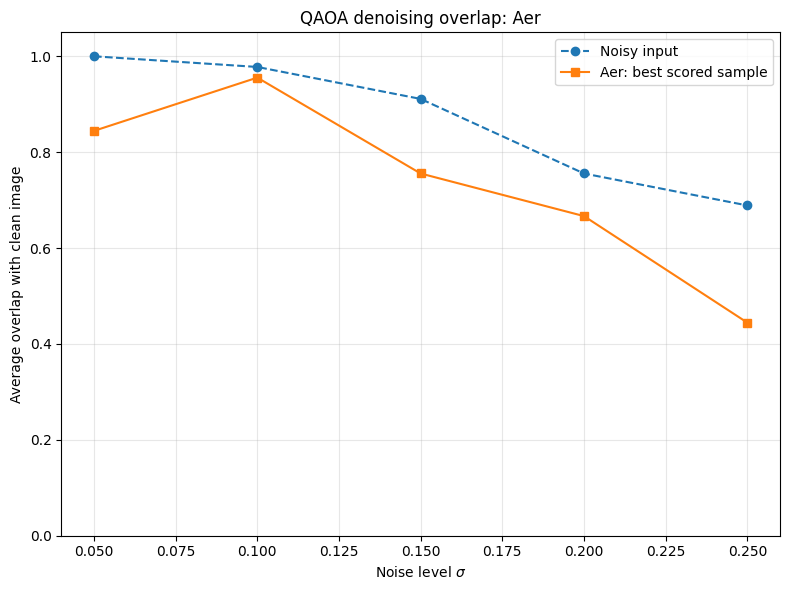

In [63]:
curve_title = (
    "QAOA denoising overlap: Aer vs IBM QPU"
    if RUN_HARDWARE
    else "QAOA denoising overlap: Aer"
)
plot_qpu_overlap_curve(summary_qpu_curve, title=curve_title)

In [64]:
def plot_qpu_circuit_cost(summary_df):
    qpu = summary_df[summary_df["backend_type"] == "IBM QPU"].sort_values("sigma")

    plt.figure(figsize=(8, 6))
    plt.plot(qpu["sigma"], qpu["depth_mean"], marker="o", label="Depth")
    plt.plot(qpu["sigma"], qpu["twoq_mean"], marker="s", label="2-qubit ops")
    plt.xlabel("Noise level $\\sigma$")
    plt.ylabel("Mean transpiled circuit cost")
    plt.title("Transpiled QPU circuit cost")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [65]:
if RUN_HARDWARE:
    plot_qpu_circuit_cost(summary_qpu_curve)

In [66]:
if RUN_HARDWARE:
    counts = data.meas.get_counts()

    qpu_post = best_scored_sample_from_counts(
        counts,
        qaoa_result=qaoa_result,
        n_visible=n_visible,
        clean_visible=clean_visible,
    )

    print("Best scored visible image:")
    print(qpu_post["best_visible"].reshape(n_side, n_side))

    print("Best scored visible overlap:", qpu_post["best_visible_overlap"])
    print("Expected visible overlap from raw QPU samples:", qpu_post["expected_visible_overlap"])
    print("Best scored energy:", qpu_post["best_energy"])

## Software

In [67]:
import sys
import platform
import importlib.metadata as md

packages = {
    "Python": None,
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "torch": "torch",
    "scikit-learn": "scikit-learn",
    "scipy": "scipy",
    "qiskit": "qiskit",
    "qiskit-aer": "qiskit-aer",
    "qiskit-ibm-runtime": "qiskit-ibm-runtime",
    "tqdm": "tqdm",
}

print("Environment versions")
print("-" * 40)
print(f"Python: {sys.version.split()[0]}")
print(f"Python executable: {sys.executable}")
print(f"Platform: {platform.platform()}")
print()

for display_name, package_name in packages.items():
    if display_name == "Python":
        continue

    try:
        version = md.version(package_name)
    except md.PackageNotFoundError:
        version = "not installed / not found"

    print(f"{display_name}: {version}")

Environment versions
----------------------------------------
Python: 3.14.0
Python executable: f:\Personal\PhD\portfolio\q-img-denoise\.venv\Scripts\python.exe
Platform: Windows-11-10.0.26200-SP0

numpy: 2.4.2
pandas: 3.0.2
matplotlib: 3.10.8
torch: 2.11.0+cu130
scikit-learn: 1.8.0
scipy: 1.17.0
qiskit: 2.3.0
qiskit-aer: 0.17.2
qiskit-ibm-runtime: 0.45.0
tqdm: 4.67.3
